# Male-vs-female clonal dynamics comparsion
- Plots:
    - Fig 1e-f
    - EDFig 2e,f,h
- Statistical tests on M/F difference (Supplemental Note)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append("../../analysis/")
sys.path.append("../../sim/")
sys.path.append("../../plot/")
sys.path.append("../../fit/")


import clones

import pickle

def save_object(obj, filename):
    with open(filename, 'wb') as outp:  # Overwrites any existing file.
        pickle.dump(obj, outp, pickle.HIGHEST_PROTOCOL)

def load_object(filename):
    with open(filename, 'rb') as outp:  # Overwrites any existing file.
        return pickle.load(outp)


from matplotlib import rcParams
# Set global font size for all axes
rcParams['axes.labelsize'] = 12
rcParams['xtick.labelsize'] = 10
rcParams['ytick.labelsize'] = 10
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


rcParams['axes.labelsize'] = 10
rcParams['xtick.labelsize'] = 7.5
rcParams['ytick.labelsize'] =  7.5
rcParams['legend.fontsize'] = 7.5
rcParams['font.size'] = 10  # General font size
rcParams['axes.titlesize'] = 10
rcParams['text.usetex'] = False
rcParams['font.family'] = 'sans-serif'
rcParams['font.sans-serif'] = ['Arial']
rcParams['svg.fonttype'] = 'none'
rcParams['lines.markersize']  = 3
rcParams['lines.linewidth']  = 1.5


sexname = {'M': 'Male', 'F': 'Female'}

def get_bootstrap_ci(bootstrap_samples, axis=0, confidence=0.95):
    """
    Calculate confidence intervals from bootstrap samples along a specified axis.
    
    Parameters:
    -----------
    bootstrap_samples : array-like
        3D array of bootstrap samples where:
        - First dimension is the number of bootstrap samples
        - Second and third dimensions are your original 2D data shape
    axis : int, default=0
        The axis of the original 2D data along which to calculate CIs
        0 = calculate CI for each column
        1 = calculate CI for each row
    confidence : float, default=0.95
        Confidence level (0 to 1)
        
    Returns:
    --------
    tuple
        (lower_bounds, upper_bounds, means)
        Each is an array corresponding to the CIs and means along the specified axis
    """
    # Convert input to numpy array if it isn't already
    samples = np.asarray(bootstrap_samples)
    
    # Calculate alpha for confidence interval
    alpha = (1 - confidence) / 2
    
    # Calculate percentiles and mean along the bootstrap samples dimension
    # Add 1 to axis because original axis 0/1 is now 1/2 due to bootstrap dimension
    lower_bounds = np.nanpercentile(samples, alpha * 100, axis=0)
    upper_bounds = np.nanpercentile(samples, (1 - alpha) * 100, axis=0)
    means = np.mean(samples, axis=0)
    
    # If axis=0 (columns), we want stats for each column of original data
    # If axis=1 (rows), we want stats for each row of original data
    if axis == 0:
        return lower_bounds, upper_bounds, means
    elif axis == 1:
        return (lower_bounds.T, upper_bounds.T, means.T)
    else:
        raise ValueError("Axis must be 0 or 1")


import tissplot as tplt
import datasets as ds


def plot_dist(d, sim_data = None, exp_data = None, tscale = None, color = 'k', xlabel = None,
                  prelabel = '', subtimes = None, subplot_axs = None,
                  im_width = 4, maxbin = None, cdf = False, bootSEs = False, overhang_in_last = True,
                  noticks = False, errmult = 1.0, ncols = 3, nolegend = False, ymax = None, xmax = None,
                  ylabel = None, yticks = None, yscale = 1.5, nogaps = False,
                  num_xticks = None, add_vlines = None, x0 = 0):
    '''
        Plots a distribution d, comparing a simulation to experimental data
        
        By default plots pdf, usless cdf = True then plots cdf
        
        If subplot_axs is None, creates a new sub-plot
        
        Specify:
            color
            ylabel
            inc_seeded = True => include seeded datapoints
            
            subtimes: indicates the indices of the experimental time-point to use      
            
            overhang_in_last: is whether last bin in pdf shown contains all higher clone sizes  
    '''    
    
    #Set-up defaults
    if xlabel is None:
        xlabel = d

    
    #Initialise simulated data
    if sim_data is not None:
        assert(sim_data.collapsed is True)
        #extract at time-points
        sdt = sim_data.data_time_crop()
        
    #Set-up timepoints
    if exp_data is not None:
        exp_data = exp_data.copy() #so manipulations don't ruin distribution
        times  = exp_data.timeq(d)
        maxpbin = exp_data.max_pdf_bin[d]
    elif sim_data is not None:
        times = sdt.timeq(d)
        maxpbin = sim_data.max_pdf_bin[d]
    else:
        print('No data provided')
        assert(0)
        
    if maxbin is None:
        maxbin = maxpbin
        
    if subtimes is not None:
        times = times[subtimes]
    else:
        subtimes = np.arange(len(times))
        
    ntimes = len(times)        
    nrows = int(np.ceil(ntimes/ncols))
        
    
    #Create sub-plots
    if subplot_axs is None:
        fig, axs = plt.subplots(nrows, ncols, figsize=(im_width*ncols, yscale*im_width*nrows), dpi=400)    
    else:
        axs = subplot_axs
        
    #Set-up dist
    if sim_data is not None:
        exp_data = sim_data
        sim_dists = exp_data.reshape_pdf(d, max_bin = maxbin + (1 - int(overhang_in_last)))
        
        if bootSEs is True:
            se_dists = exp_data.bootstrap_SEs(d, exp_data.nsamples[d], sedists = True)*errmult
                    
        if cdf is True:
            sim_dists = ds.getCdf(sim_dists)
        exp_data = None
    
    if exp_data is not None:
        exp_dists = exp_data.reshape_pdf(d, max_bin = maxbin + (1 - int(overhang_in_last)))
        
        if bootSEs is True:
            exp_se_dists = exp_data.bootstrap_SEs(d, exp_data.nsamples[d], sedists = True)*errmult
        
        if cdf is True:
            exp_dists = ds.getCdf(exp_dists)
    
    for t in range(ntimes):
        xx = int(np.floor((t + x0)/ncols))
        yy = (t + x0) % ncols 
        tt = subtimes[t]
        
        if ntimes > ncols:
            ax = axs[xx,yy]
        elif ncols > 1:
            ax = axs[yy]
        else:
            ax = axs
            
        #Plotting simulation data
        if sim_data is not None:
            ax.plot(np.arange(0, maxbin + 1), sim_dists[tt, 0:(maxbin+1)], '-', label = prelabel, color = color, alpha = 0.8)
            if bootSEs is True:
                ax.fill_between(np.arange(0, maxbin + 1), sim_dists[tt, 0:(maxbin+1)] - se_dists[tt, 0:(maxbin+1)], 
                    sim_dists[tt, 0:(maxbin+1)] + se_dists[tt, 0:(maxbin+1)], color = color, alpha = 0.3)
        
        
        #Plotting experimental data
        if exp_data is not None:   
            if bootSEs is True:
                ax.errorbar(np.arange(0, maxbin + 1), exp_dists[tt, 0:(maxbin+1)], exp_se_dists[tt, 0:(maxbin+1)], fmt = 'o', label = '_nolegend_', color = color)
            else:
                ax.plot(np.arange(0, maxbin + 1), exp_dists[tt, 0:(maxbin+1)], 'o', label = '_nolegend_', color = color)
        
        ax.set_title('Day ' + str(int(times[t]))) 

        if add_vlines is not None:
            if np.ndim(ymax) > 0:
                for vl in add_vlines:
                    ax.vlines(vl, 0, ymax[t], color = 'k', linestyle = '-', alpha = 0.1)
            else:
                for vl in add_vlines:
                    ax.vlines(vl, 0, ymax, color = 'k', linestyle = '-', alpha = 0.1)

        if ymax is not None:
            if np.ndim(ymax) > 0:
                ax.set_ylim([0,ymax[t]])
            else:
                ax.set_ylim([0,ymax])

        if xmax is not None:
            if np.ndim(xmax) > 0:
                ax.set_xlim([0,xmax[t]])
                if num_xticks is not None:
                    xticks = np.linspace(0, xmax[t], num_xticks).astype(int)
                    if yy < ncols - 1:
                        xticks = xticks[:-1]
                    else:
                        xticks = xticks[:]
                    ax.set_xticks(xticks)                
            else:
                ax.set_xlim([0,xmax])
                if num_xticks is not None:
                    xticks = np.linspace(0, xmax, num_xticks).astype(int)
                    if yy < ncols - 1:
                        xticks = xticks[:-1]
                    else:
                        xticks = xticks[:]                        
                    ax.set_xticks(xticks)

        
        if nolegend is False:       
            ax.legend(loc = 'upper right', frameon = False)
        
        if noticks:
            ax.set_xticks([])
            ax.set_yticks([])

        if yticks is not None:
            if np.ndim(yticks) > 0 and np.ndim(yticks[0]) > 0:
                ax.set_yticks(yticks[t])
            else:
                if yy == 0:
                    ax.set_yticks(yticks)
                else:
                    ax.set_yticks([])
        
        if yy == 0:
            if ylabel is not None:
                ax.set_ylabel(ylabel)     
            else:
                if cdf:
                    ax.set_ylabel('P(' + xlabel + ' < X)')
                else:
                    ax.set_ylabel('P(' + xlabel + ')')
        
        if yy == 0:
            ax.set_xlabel(xlabel)

        

    plt.subplots_adjust(hspace=0.3)
    plt.tight_layout()

    if nogaps:
        plt.subplots_adjust(wspace=0, hspace=0)

    
    return axs



def plot_dist(d, sim_data = None, exp_data = None, tscale = None, color = 'k', xlabel = None,
                  plot_seeded = False, prelabel = '', subtimes = None, subplot_axs = None,
                  im_width = 4, maxbin = None, cdf = False, bootSEs = False, overhang_in_last = True,
                  noticks = False, errmult = 1.0, ncols = 3, nolegend = False, ymax = None, xmax = None,
                  ylabel = None, yticks = None, yscale = 1.5, nogaps = False,
                  num_xticks = None, add_vlines = None, x0 = 0, nrows = None):
    '''
        Plots a distribution d, comparing a simulation to experimental data
        
        By default plots pdf, usless cdf = True then plots cdf
        
        If subplot_axs is None, creates a new sub-plot
        
        Specify:
            color
            ylabel
            inc_seeded = True => include seeded datapoints
            
            subtimes: indicates the indices of the experimental time-point to use      
            
            overhang_in_last: is whether last bin in pdf shown contains all higher clone sizes  
    '''    
    
    #Set-up defaults
    if xlabel is None:
        xlabel = d

    
    #Initialise simulated data
    if sim_data is not None:
        assert(sim_data.collapsed is True)
        #extract at time-points
        sdt = sim_data.data_time_crop()
        
    #Set-up timepoints
    if exp_data is not None:
        exp_data = exp_data.copy() #so manipulations don't ruin distribution
        times  = exp_data.timeq(d)
        if d in exp_data.max_pdf_bin:
            maxpbin = exp_data.max_pdf_bin[d]
        else:
            maxpbin = 200
    elif sim_data is not None:
        times = sdt.timeq(d)
        if d in sim_data.max_pdf_bin:
            maxpbin = sim_data.max_pdf_bin[d]
        else:
            maxpbin = 200        
    else:
        print('No data provided')
        assert(0)
        
    if maxbin is None:
        maxbin = maxpbin
        
    if subtimes is not None:
        times = times[subtimes]
    else:
        subtimes = np.arange(len(times))
        
    ntimes = len(times)        

    if nrows is None:
        nrows = int(np.ceil(ntimes/ncols))
    
    #Create sub-plots
    if subplot_axs is None:
        fig, axs = plt.subplots(nrows, ncols, figsize=(im_width*ncols, yscale*im_width*nrows), dpi=400)    
    else:
        axs = subplot_axs
        
    #Set-up dist
    if sim_data is not None:
        exp_data = sim_data
        sim_dists = exp_data.reshape_pdf(d, max_bin = maxbin + (1 - int(overhang_in_last)))
        
        if bootSEs is True:
            se_dists = exp_data.bootstrap_SEs(d, exp_data.nsamples[d], sedists = True)*errmult
                    
        if cdf is True:
            sim_dists = ds.getCdf(sim_dists)
        exp_data = None
    
    if exp_data is not None:
        exp_dists = exp_data.reshape_pdf(d, max_bin = maxbin + (1 - int(overhang_in_last)))
        
        if bootSEs is True:
            exp_se_dists = exp_data.bootstrap_SEs(d, exp_data.nsamples[d], sedists = True)*errmult
        
        if cdf is True:
            exp_dists = ds.getCdf(exp_dists)
    
    for t in range(ntimes):
        xx = int(np.floor((t + x0)/ncols))
        yy = (t + x0) % ncols 
        tt = subtimes[t]
        
        if nrows > 1:
            ax = axs[xx,yy]
        elif ncols > 1:
            ax = axs[yy]
        else:
            ax = axs
            
        #Plotting simulation data
        if sim_data is not None:
            ax.plot(np.arange(0, maxbin + 1), sim_dists[tt, 0:(maxbin+1)], '-', label = prelabel, color = color, alpha = 0.8)
            if bootSEs is True:
                ax.fill_between(np.arange(0, maxbin + 1), sim_dists[tt, 0:(maxbin+1)] - se_dists[tt, 0:(maxbin+1)], 
                    sim_dists[tt, 0:(maxbin+1)] + se_dists[tt, 0:(maxbin+1)], color = color, alpha = 0.3)
        
        #Plotting experimental data
        if exp_data is not None:   
            if bootSEs is True:
                ax.errorbar(np.arange(0, maxbin + 1), exp_dists[tt, 0:(maxbin+1)], exp_se_dists[tt, 0:(maxbin+1)], fmt = 'o', label = '_nolegend_', color = color)
            else:
                ax.plot(np.arange(0, maxbin + 1), exp_dists[tt, 0:(maxbin+1)], 'o', label = '_nolegend_', color = color)
        
        if xx == 0:
            ax.set_title('D' + str(int(times[t]))) 

        if add_vlines is not None:
            if np.ndim(ymax) > 0:
                for vl in add_vlines:
                    ax.addvlines(vl, 0, ymax[t], color = 'k', linestyle = '-', alpha = 0.1)
            else:
                for vl in add_vlines:
                    ax.vlines(vl, 0, ymax, color = 'k', linestyle = '-', alpha = 0.1)

        if ymax is not None:
            if np.ndim(ymax) > 0:
                ax.set_ylim([0,ymax[t]])
            else:
                ax.set_ylim([0,ymax])

        if xmax is not None:
            if np.ndim(xmax) > 0:
                ax.set_xlim([0,xmax[t]])
                if num_xticks is not None:
                    xticks = np.linspace(0, xmax[t], num_xticks).astype(int)
                    if yy < ncols - 1:
                        xticks = xticks[:-1]
                    else:
                        xticks = xticks[:]
                    if xx == nrows - 1:
                        ax.set_xticks(xticks)   
                    else:
                        ax.set_xticks([])                                     
            else:
                ax.set_xlim([0,xmax])
                if num_xticks is not None:
                    xticks = np.linspace(0, xmax, num_xticks).astype(int)
                    if yy < ncols - 1:
                        xticks = xticks[:-1]
                    else:
                        xticks = xticks[:]                        
                    if xx == nrows - 1:
                        ax.set_xticks(xticks)
                    else:
                        ax.set_xticks([])

        
        if nolegend is False:       
            ax.legend(loc = 'upper right', frameon = False)
        
        if noticks:
            ax.set_xticks([])
            ax.set_yticks([])

        if yticks is not None:
            if np.ndim(yticks) > 0 and np.ndim(yticks[0]) > 0:
                ax.set_yticks(yticks[t])
            else:
                if yy == 0:
                    if xx == 0:
                        ax.set_yticks(yticks)
                    else:
                        ax.set_yticks(np.array(yticks)[:-1])
                else:
                    ax.set_yticks([])
        
        if yy == 0 and xx == 0:
            if ylabel is not None:
                ax.set_ylabel(ylabel)     
            else:
                if cdf:
                    ax.set_ylabel('P(' + xlabel + ' < X)')
                else:
                    ax.set_ylabel('P(' + xlabel + ')')
        
        if yy == 0 and xx == nrows - 1:
            ax.set_xlabel(xlabel)

        

    plt.subplots_adjust(hspace=0.3)
    plt.tight_layout()

    if nogaps:
        plt.subplots_adjust(wspace=0, hspace=0)

    return axs

In [2]:
#Load clonal data

exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

exp_data_F = load_object(exp_folder + 'data_ctr_F.pkl')
livesize_F = exp_data_F['livesize'].copy()

exp_data_M = load_object(exp_folder + 'data_ctr_M.pkl')
livesize_M = exp_data_M['livesize'].copy()

colm = {'M30': 'r', 'M1': 'b', 'M14': 'g', 'M3': 'tab:orange', 'M1bis': 'tab:purple',
        'F3':  'r', 'F4': 'b', 'F11': 'g', 'F9': 'tab:orange', 'F10': 'tab:purple'}
fmice = ['F3', 'F4', 'F11', 'F9', 'F10']
mmice = ['M30', 'M1', 'M14', 'M3', 'M1bis']
sexes = ['F', 'M']

tvals = exp_data['ctrTimeClonesize']

sexes = ['M', 'F']
ct = 'ctr'
col = {'M': 'r', 'F': 'b', '': 'k'}

savefolder = 'Figures/Fig1_even_odd/'

In [3]:
clone_anal_F = clones.xanalysis(livesize_F, verbose=False, tvals=exp_data['ctrTimeClonesize'])
clone_anal_M = clones.xanalysis(livesize_M, verbose=False, tvals=exp_data['ctrTimeClonesize'])

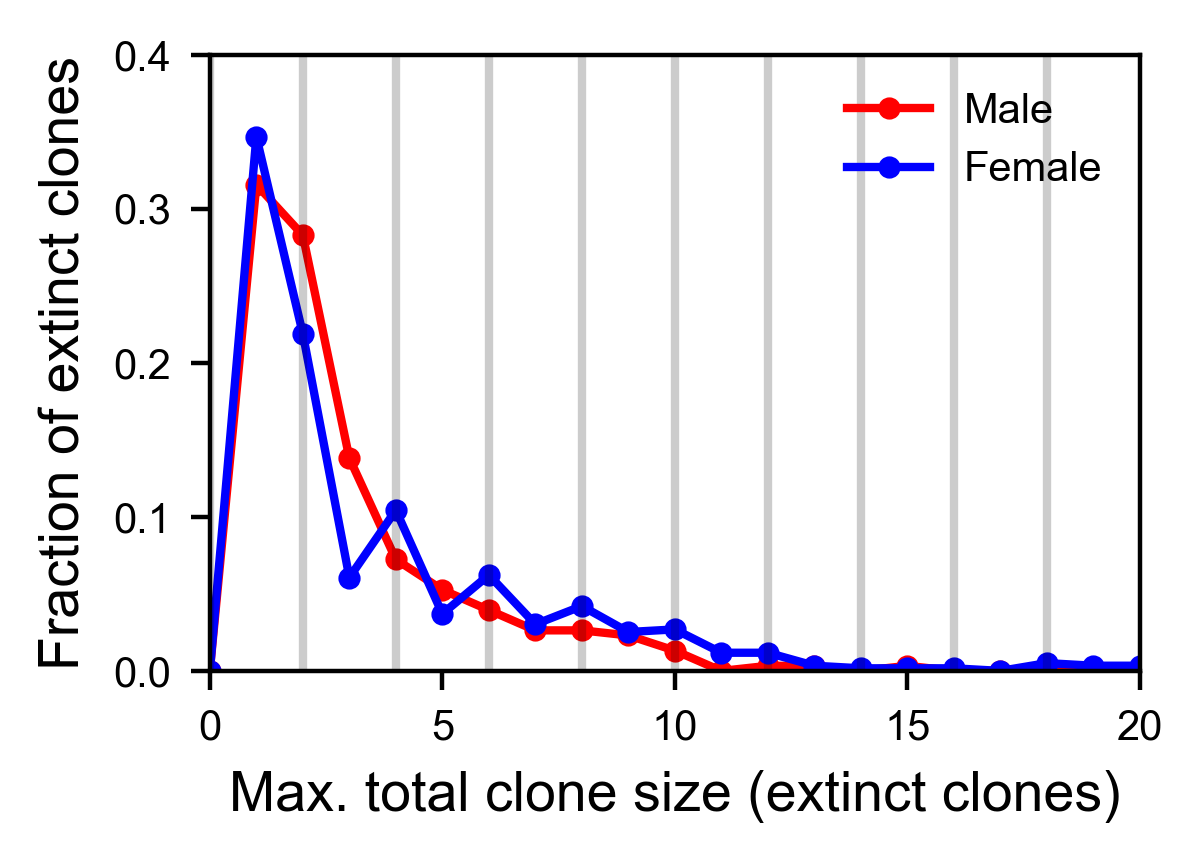

In [4]:
plt.figure(figsize=(3, 2), dpi=400)
plt.plot(clone_anal_M.xfrac(), 'r-o')
plt.plot(clone_anal_F.xfrac(), 'b-o')
plt.xlabel('Max. total clone size (extinct clones)')
plt.ylabel('Fraction of extinct clones')
plt.vlines(np.arange(0,20,2), 0, 1, color='k', linestyle='-', alpha=0.2)
plt.ylim([0, 0.4])
plt.xlim([0,20])
plt.legend(['Male', 'Female'], loc='upper right', frameon=False)
plt.savefig(savefolder + 'Fig2_frac_total_clonesize.pdf', dpi=400, bbox_inches='tight')
plt.show()

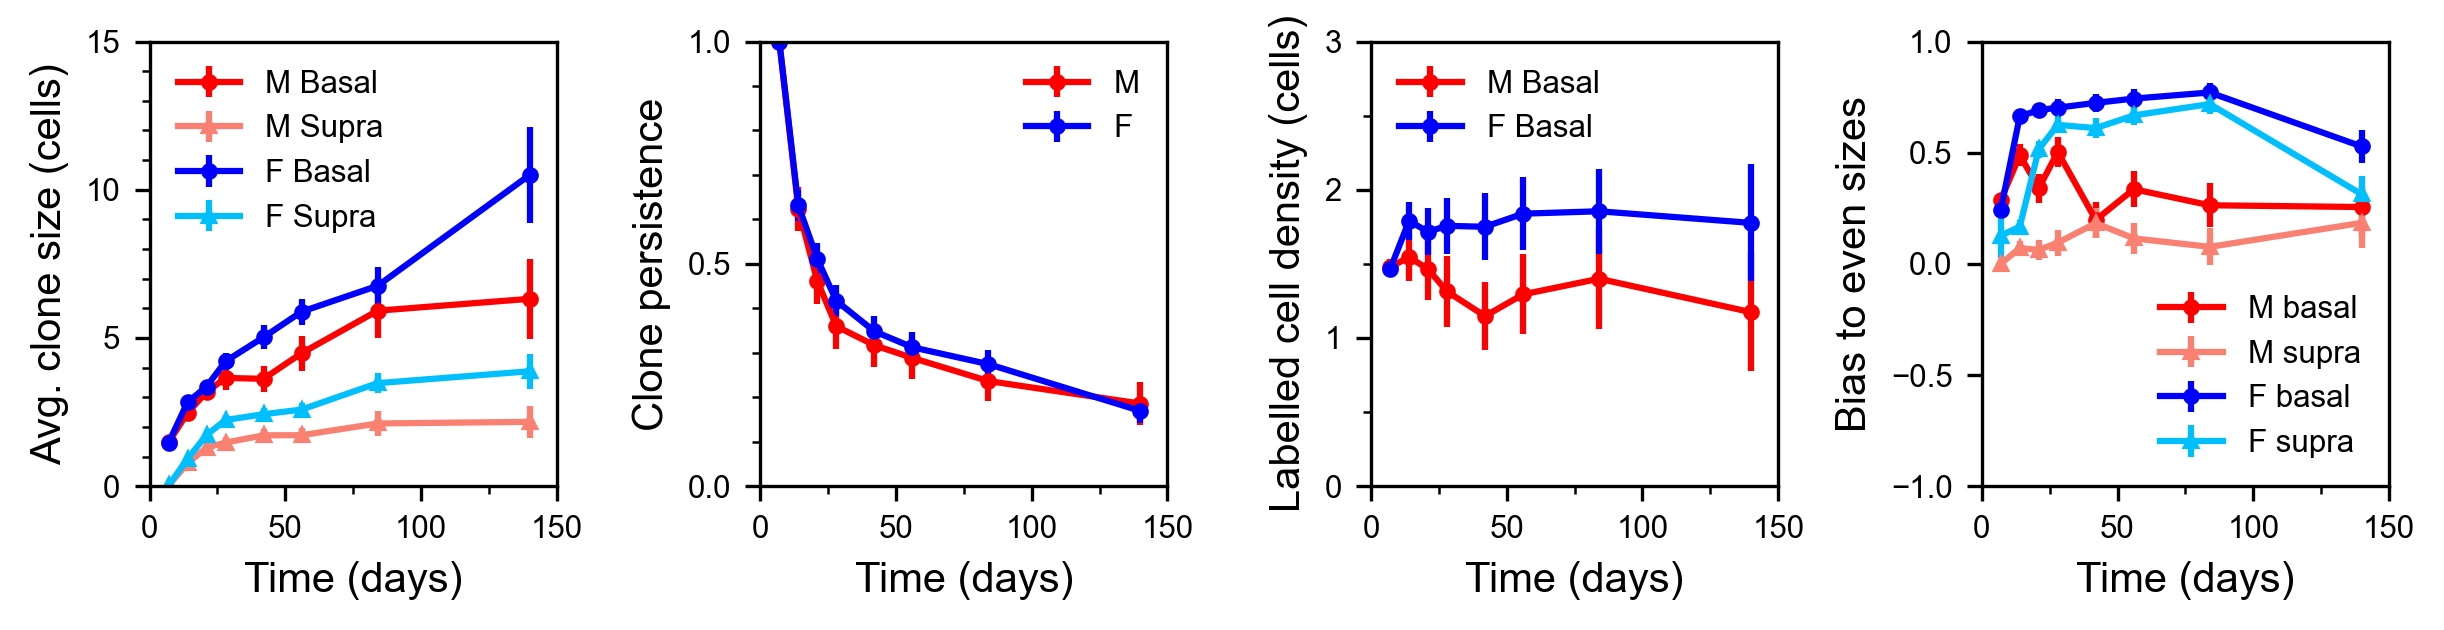

In [5]:
nboots = 5000
exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']

col = {'M': 'r', 'F': 'b'}
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}

conf = 0.68

fig, axes = plt.subplots(1, 4, figsize=(8.25, 2.2), dpi=300)
for sex in ['M', 'F']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    # Subplot 1: Average Clone Size
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('av_bas_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[0].errorbar(clone_anal.tvals, clone_anal.av_bas_cs, upper68-lower68, fmt=f'{col[sex]}o-', label=f'{sex} Basal')
    db = clone_anal.boot('av_sup_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[0].errorbar(clone_anal.tvals, clone_anal.av_sup_cs, upper68-lower68, fmt=f'^-', color = sec_cols[sex], label=f'{sex} Supra')
axes[0].set_xlabel('Time (days)')
axes[0].set_ylabel('Avg. clone size (cells)')
axes[0].legend(frameon=False, fontsize=7.5, loc='upper left')
axes[0].set_ylim([0, 15])
axes[0].set_yticks(np.arange(0, 16, 5))
axes[0].set_yticks(np.arange(0, 16, 1), minor=True)
axes[0].set_xlim([0, 150])
axes[0].set_xticks(np.arange(0, 151, 50))
axes[0].set_xticks(np.arange(0, 151, 25), minor=True)

# Subplot 2: Labelled Cell Density
for sex in ['M', 'F']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('lcd', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[2].errorbar(clone_anal.tvals, clone_anal.lcd, upper68-lower68, fmt=f'{col[sex]}o-', label = f'{sex} Basal')
    db = clone_anal.boot('av_full_sup_cs', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    #axes[2].errorbar(clone_anal.tvals, clone_anal.av_full_sup_cs, upper68-lower68, fmt=f'{col[sex]}^--', label=f'{sex} Supra')    
axes[2].set_xlabel('Time (days)')
axes[2].set_ylabel('Labelled cell density (cells)')
axes[2].legend(frameon=False, fontsize=7.5, loc='upper left')
axes[2].set_ylim([0, 3])
axes[2].set_yticks(np.arange(0, 3.1, 1))
axes[2].set_yticks(np.arange(0, 3.1, 0.5), minor=True)
axes[2].set_xlim([0, 150])
axes[2].set_xticks(np.arange(0, 151, 50))
axes[2].set_xticks(np.arange(0, 151, 25), minor=True)

# Subplot 3: Persistence
for sex in ['M', 'F']:
    exp_data = load_object(exp_folder + f'data_ctr_{sex}.pkl')
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose=False, tvals=exp_data['ctrTimeClonesize'])
    db = clone_anal.boot('pers', nboots, None, sample_size=None)
    lower68, upper68, means68 = get_bootstrap_ci(db, 0, confidence=conf)
    axes[1].errorbar(clone_anal.tvals, clone_anal.pers, upper68-lower68, fmt=f'{col[sex]}o-', label = f'{sex}')
axes[1].set_xlabel('Time (days)')
axes[1].set_ylabel('Clone persistence')
axes[1].set_ylim([0, 1])
axes[1].set_yticks(np.arange(0, 1.1, 0.5))
axes[1].set_yticks(np.arange(0, 1.1, 0.1), minor=True)
axes[1].set_xlim([0, 150])
axes[1].set_xticks(np.arange(0, 151, 50))
axes[1].set_xticks(np.arange(0, 151, 25), minor=True)
axes[1].legend(frameon=False, fontsize=7.5, loc='upper right')


for sex in ['M', 'F']:
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    axes[3].errorbar(clone_anal.tvals, clone_anal.ev_bas_cs, clone_anal.boot('ev_bas_cs'), fmt='o-',  color = col[sex], label = f'{sex} basal')
    axes[3].errorbar(clone_anal.tvals, clone_anal.ev_sup_cs, clone_anal.boot('ev_sup_cs'), fmt='^-', color = sec_cols[sex], label = f'{sex} supra')

axes[3].set_xlabel('Time (days)')
axes[3].set_ylabel('Bias to even sizes')
axes[3].set_ylim([-1,1])
axes[3].set_xlim([0,150])
axes[3].set_xticks(np.arange(0, 151, 50))
axes[3].set_xticks(np.arange(0, 151, 25), minor=True)
axes[3].legend(frameon = False, loc = 'lower right', fontsize=7.5)

plt.tight_layout()
plt.subplots_adjust(wspace = 0.5)
plt.savefig('Figures/F2abc_M_F_av.pdf')
plt.show()


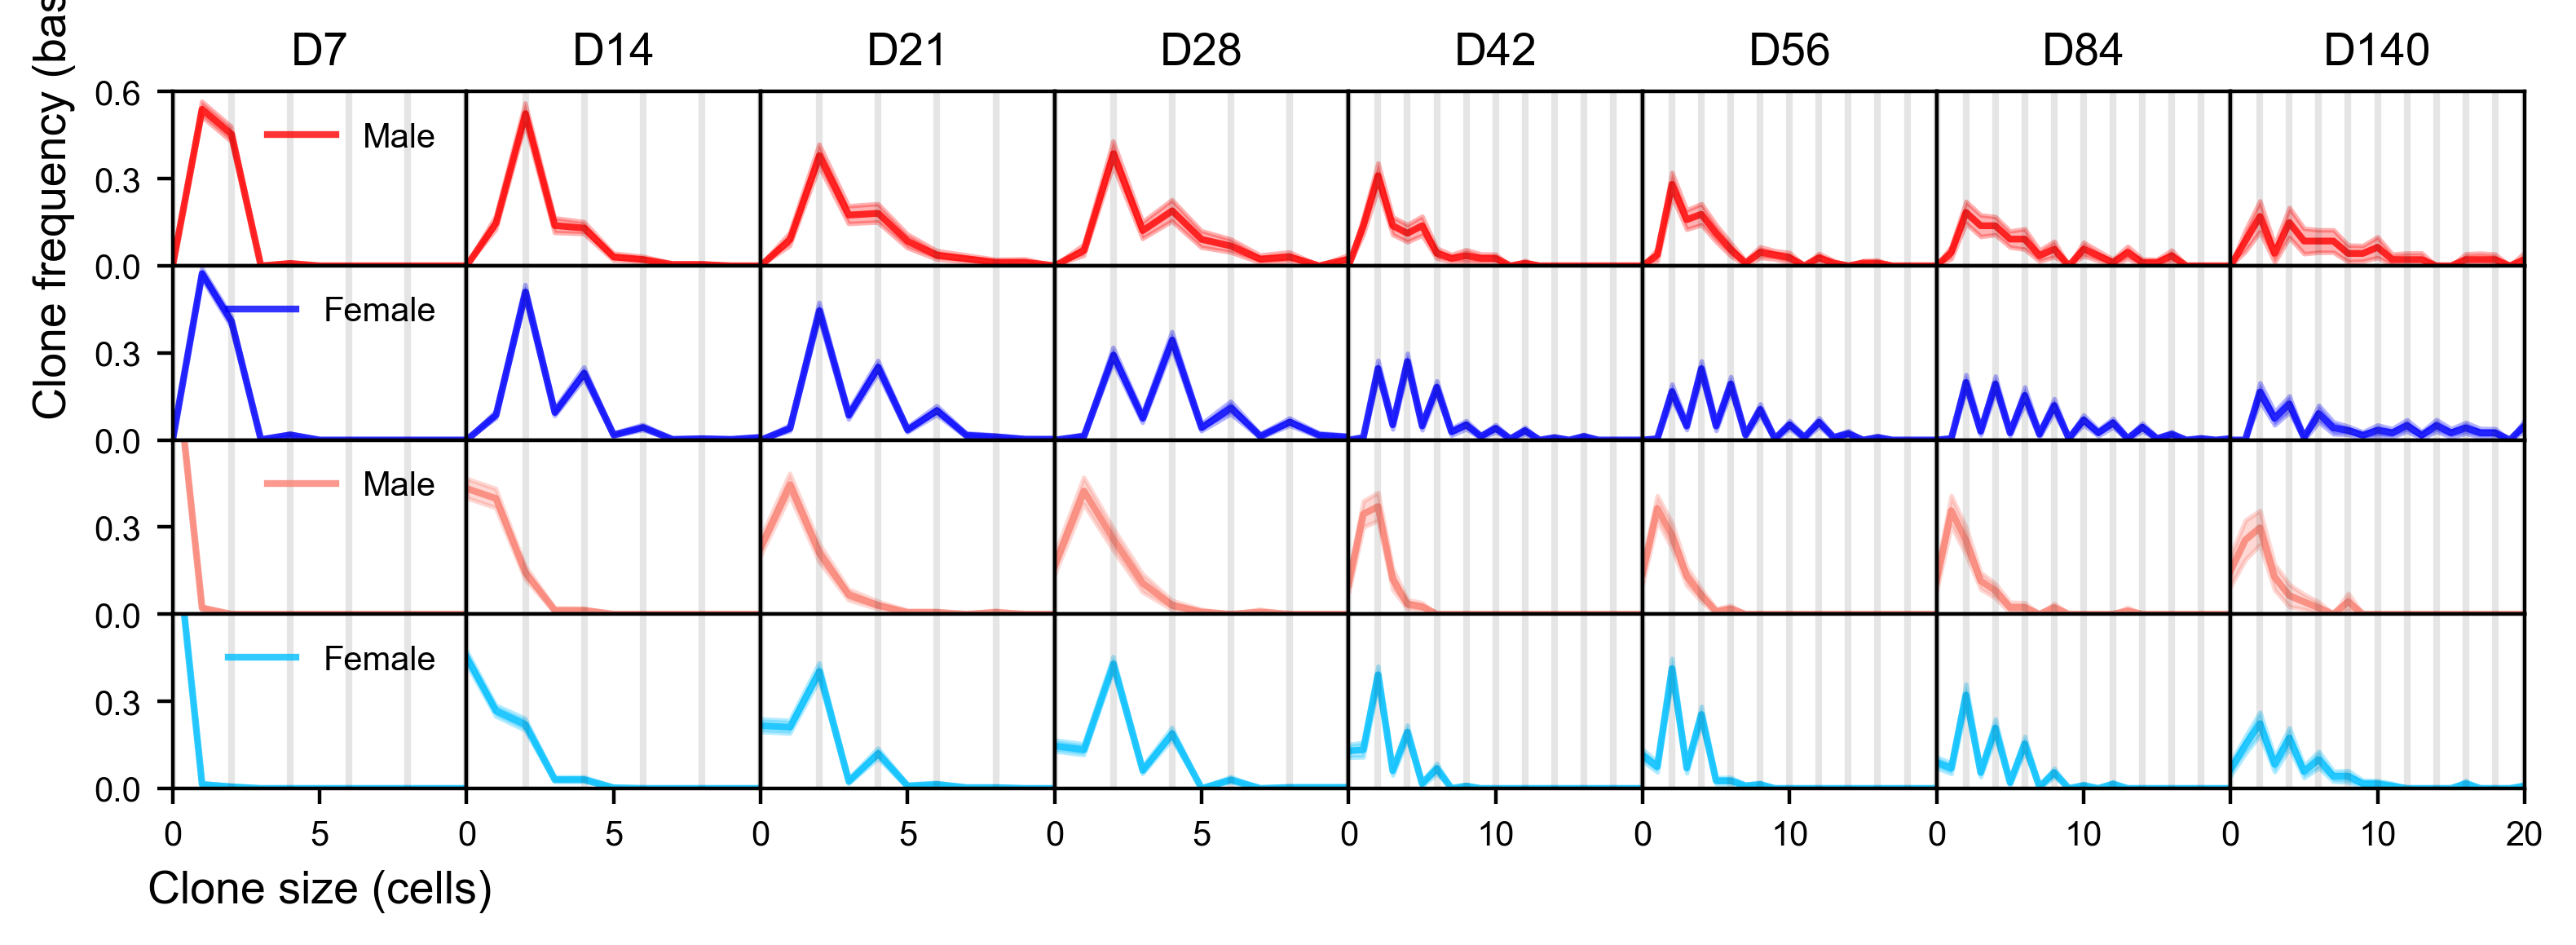

In [6]:
ct = 'ctr'
exp_folder = '../../experiment/homeo/'
sec_cols = {'M': 'salmon', 'F': 'deepskyblue', 'castre': 'violet'}

cols = {'M': 'r', 'F': 'b', '': 'k'}
sexes = ['M', 'F']


ys = 0.75
iw = 1.0



sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= None, maxbin = 100, cdf = False, 
        xlabel= 'Clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10,10,10,10,20,20,20,20],
                    ylabel = 'Clone frequency (basal)', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), nrows = 4)  


sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= None, maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10,10,10,10,20,20,20,20],                    
                ylabel = 'Fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 8,
                    nrows = 4)  


sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= None, maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10,10,10,10,20,20,20,20], nolegend = True, yscale = ys, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 16,
                    nrows = 4, ylabel = 'Clone frequency (supra)')  


sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= None, maxbin = 100, cdf = False, 
        xlabel= 'Clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{sec_cols[sex]}',
                ncols=8, im_width = iw, ymax = 0.6, xmax = [10,10,10,10,20,20,20,20],                    
                ylabel = 'Fraction', nolegend = True, yscale = ys, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 24,
                    nrows = 4)  

axs[0,0].legend(loc='upper right', frameon=False)
axs[1,0].legend(loc='upper right', frameon=False)
axs[2,0].legend(loc='upper right', frameon=False)
axs[3,0].legend(loc='upper right', frameon=False)
plt.savefig(savefolder + 'SF3_all_dists.pdf')


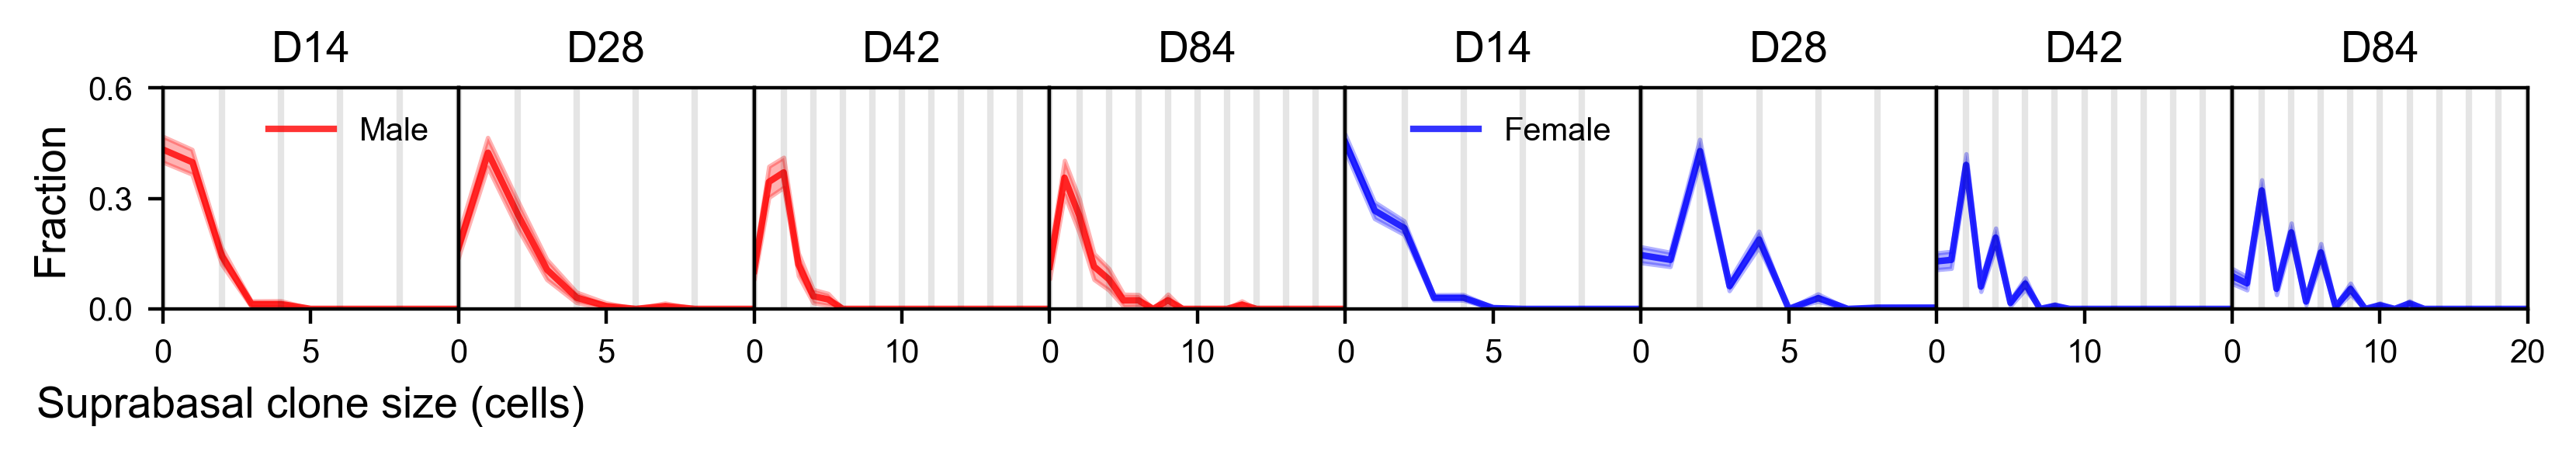

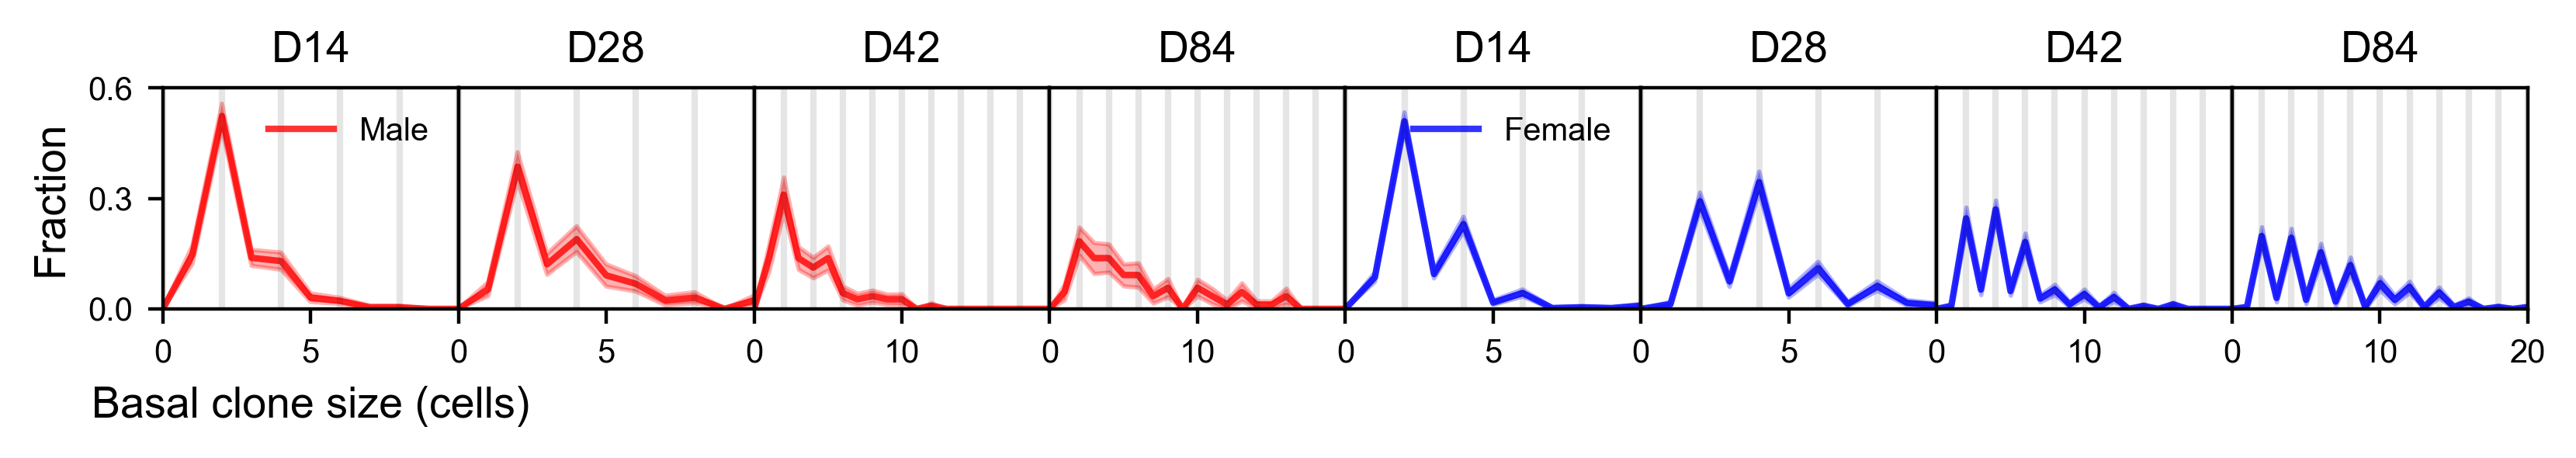

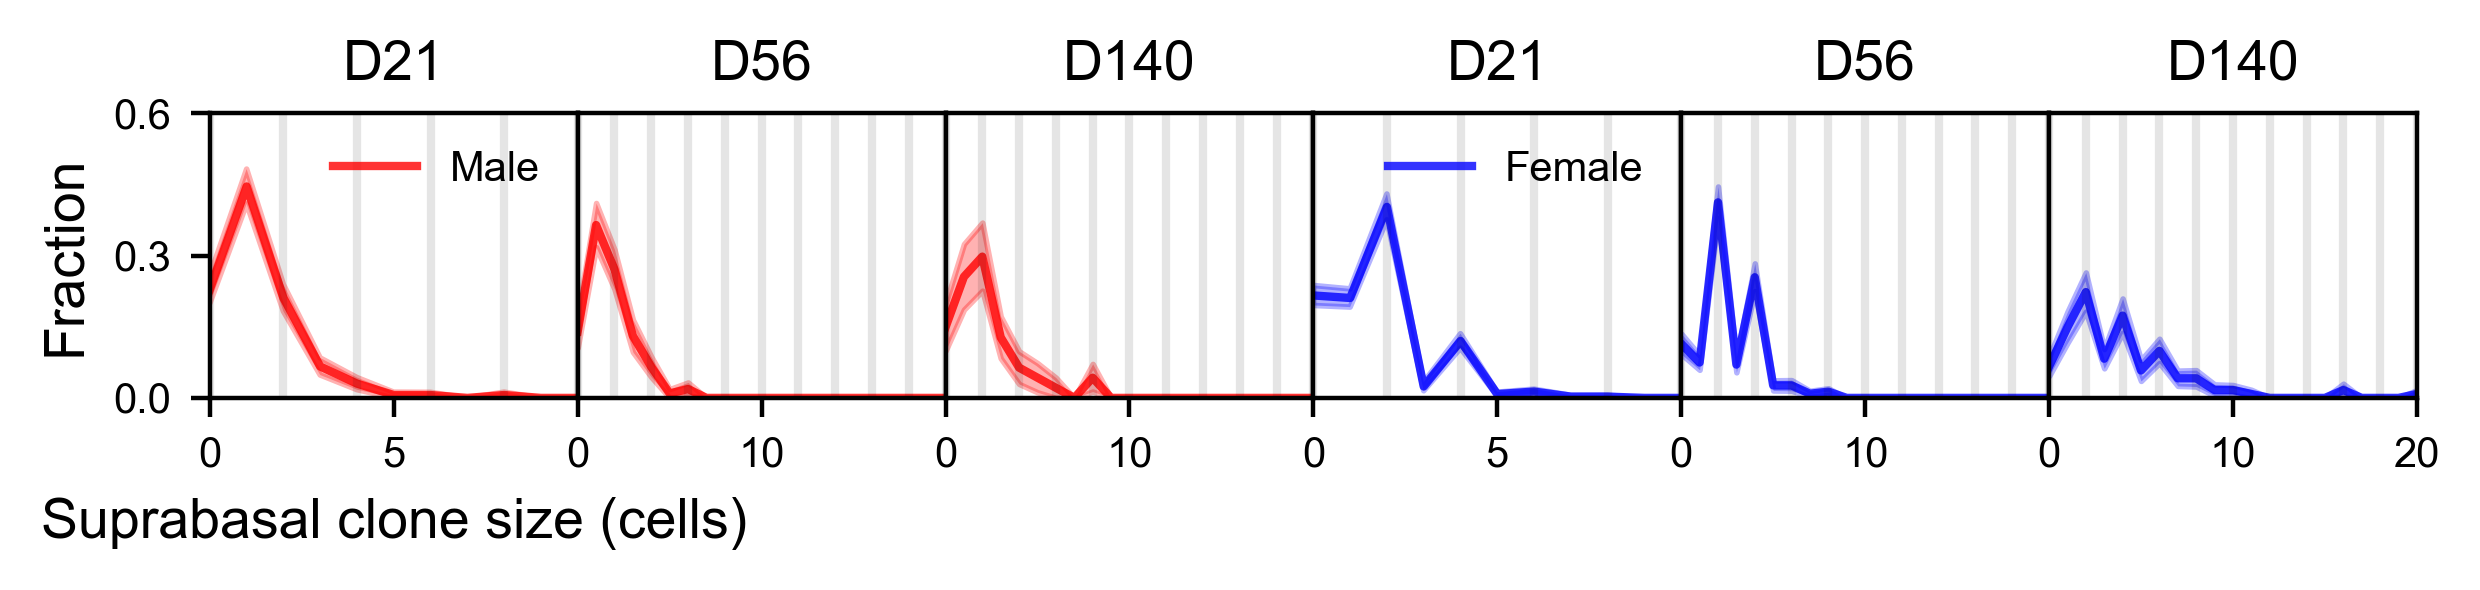

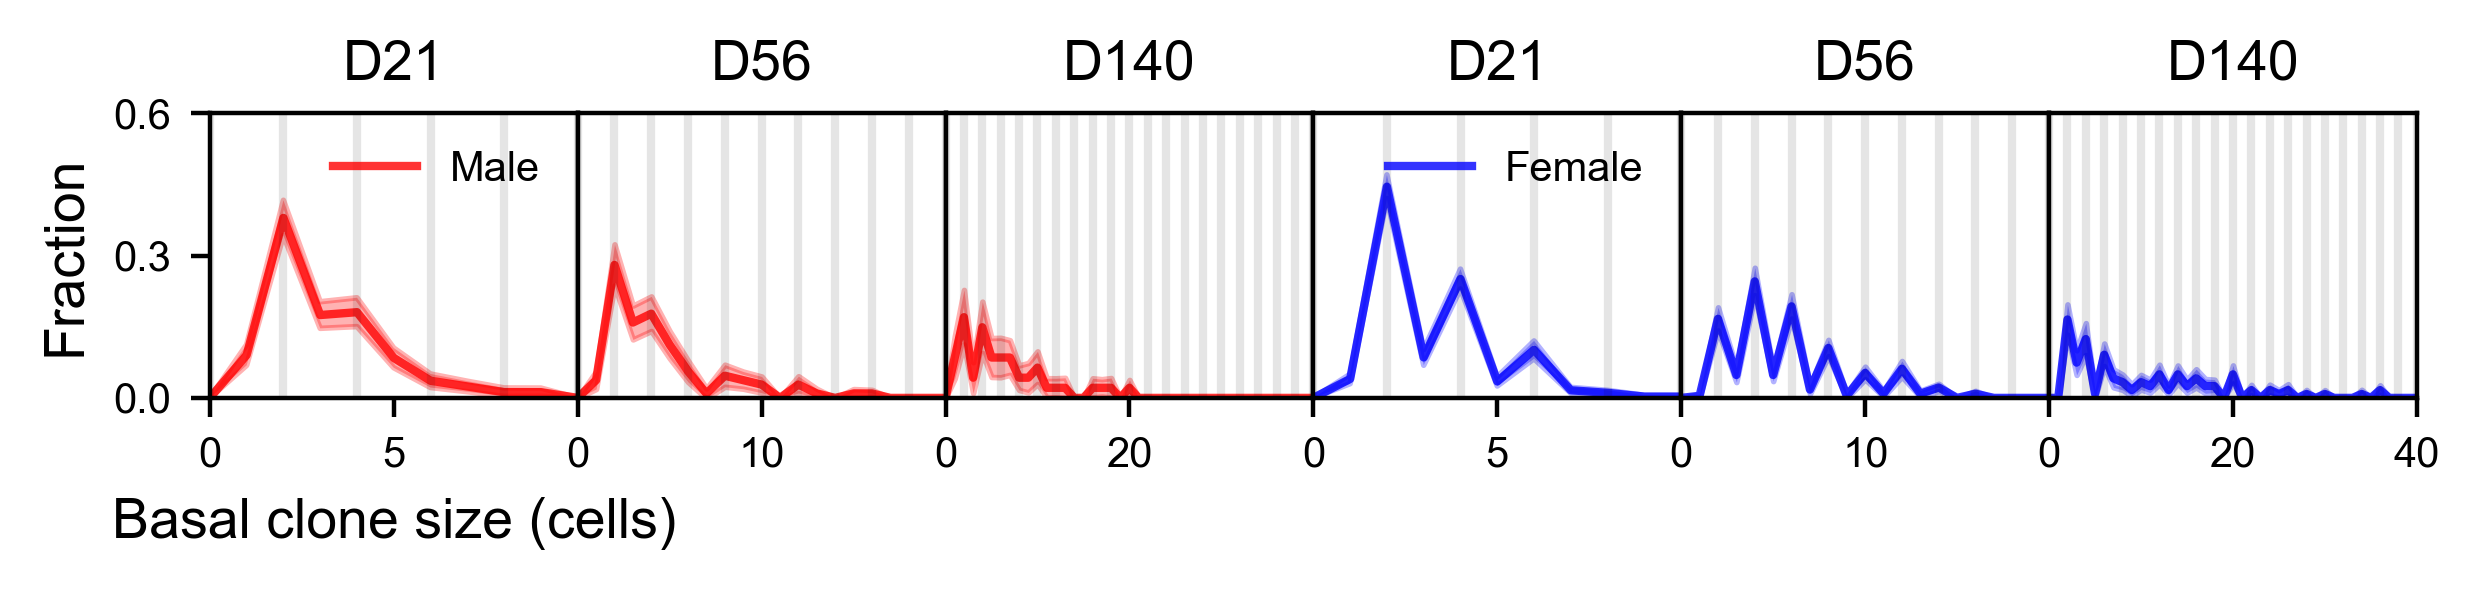

In [7]:
''' 
    Plot distributions
'''

ct = 'ctr'
exp_folder = '../../experiment/homeo/'

cols = {'M': 'r', 'F': 'b', '': 'k'}
sexes = ['M', 'F']

sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [1,3,4,6], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10,10,20,20],
                    ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                     yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2))  

sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [1,3,4,6], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10,10,20,20],
                    ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 4)  
axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
plt.savefig(savefolder + 'F1_supra.pdf')



sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [1,3,4,6], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 101, 2))    


sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [1,3,4,6], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=8, im_width = 1.05, ymax = 0.6, xmax = [10, 10, 20, 20],
                ylabel = 'Clone fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True,
                yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 101, 2), subplot_axs = axs, x0 = 4)  

axs[0].legend(loc='upper right', frameon=False)
axs[4].legend(loc='upper right', frameon=False)
plt.savefig(savefolder + 'F1_basal.pdf')





sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [2,5,7], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=6, im_width = 1.05, ymax = 0.6, xmax = [10,20,20],
         ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2))  
sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [2,5,7], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=6, im_width = 1.05, ymax = 0.6, xmax = [10,20,20],
                        ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 3)  
axs[0].legend(loc='upper right', frameon=False)
axs[3].legend(loc='upper right', frameon=False)
plt.savefig(savefolder + 'SF1_supra_rest.pdf')




sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [2,5,7], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=6, im_width = 1.05, ymax = 0.6, xmax = [10,20,40],
         ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2))    
sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [2,5,7], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sexname[sex]}', bootSEs=True, color = f'{cols[sex]}',
                ncols=6, im_width = 1.05, ymax = 0.6, xmax = [10,20,40],
                    ylabel = 'Fraction', nolegend = True, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.3, 0.6], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 3)  

axs[0].legend(loc='upper right', frameon=False)
axs[3].legend(loc='upper right', frameon=False)
plt.savefig(savefolder + 'SF1_basal_rest.pdf')


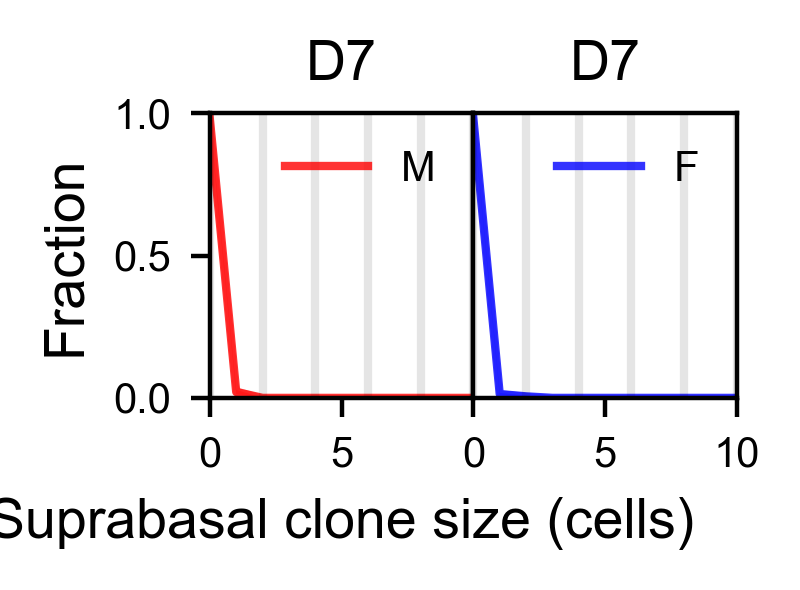

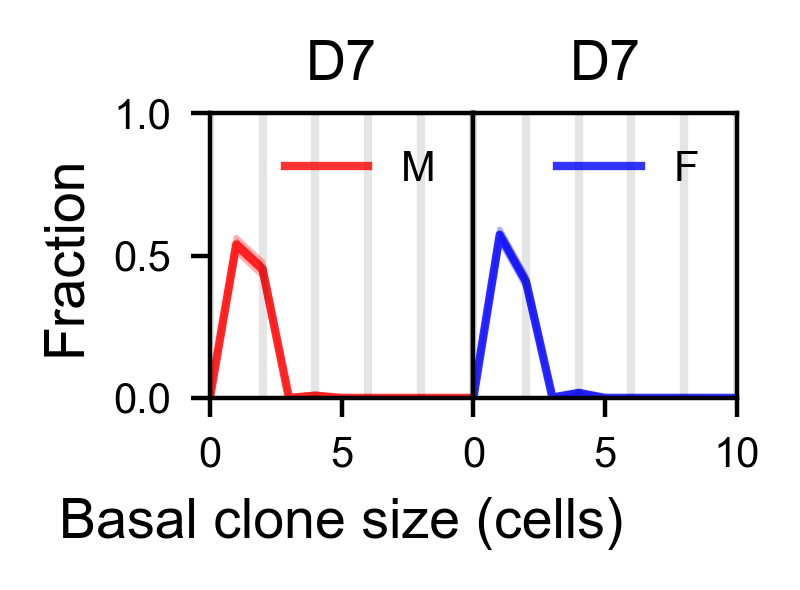

In [8]:

sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [0], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sex}', bootSEs=True, color = f'{cols[sex]}',
                ncols=2, im_width = 1.05, ymax = 1.0, xmax = [10,20,20],
         ylabel = 'Fraction', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.5, 1.0], add_vlines = np.arange(0, 80, 2))  
sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('supraCS', exp_data, None, subtimes= [0], maxbin = 100, cdf = False, 
        xlabel= 'Suprabasal clone size (cells)', prelabel= f'{sex}', bootSEs=True, color = f'{cols[sex]}',
                ncols=2, im_width = 1.05, ymax = 1.0, xmax = [10,20,20],
                        ylabel = 'Fraction', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.5, 1.0], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 1)  
plt.savefig(savefolder + 'SF1_supra_D0.pdf')




sex = 'M'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [0], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sex}', bootSEs=True, color = f'{cols[sex]}',
                ncols=2, im_width = 1.05, ymax = 1.0, xmax = [10,20,40],
         ylabel = 'Fraction', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.5, 1.0], add_vlines = np.arange(0, 80, 2))    
sex = 'F'
exp_file = exp_folder + 'data_' + ct + '_' + sex + '.pkl'
exp_data = ds.exp_dataset(exp_file, 'ctr', toCalculate = ['basalCS', 'supraCS'],)
exp_data.reshape_pdfs(50) #re-shapes pdfs to have 2 zeros as last elements

axs = plot_dist('basalCS', exp_data, None, subtimes= [0], maxbin = 100, cdf = False, 
        xlabel= 'Basal clone size (cells)', prelabel= f'{sex}', bootSEs=True, color = f'{cols[sex]}',
                ncols=2, im_width = 1.05, ymax = 1.0, xmax = [10,20,40],
                    ylabel = 'Fraction', nolegend = False, yscale = 1.5, num_xticks = 3, nogaps = True, 
                    yticks = [0, 0.5, 1.0], add_vlines = np.arange(0, 80, 2), subplot_axs = axs, x0 = 1)  

plt.savefig(savefolder + 'SF1_basal_D0.pdf')


Text(0.5, 1.0, 'D84')

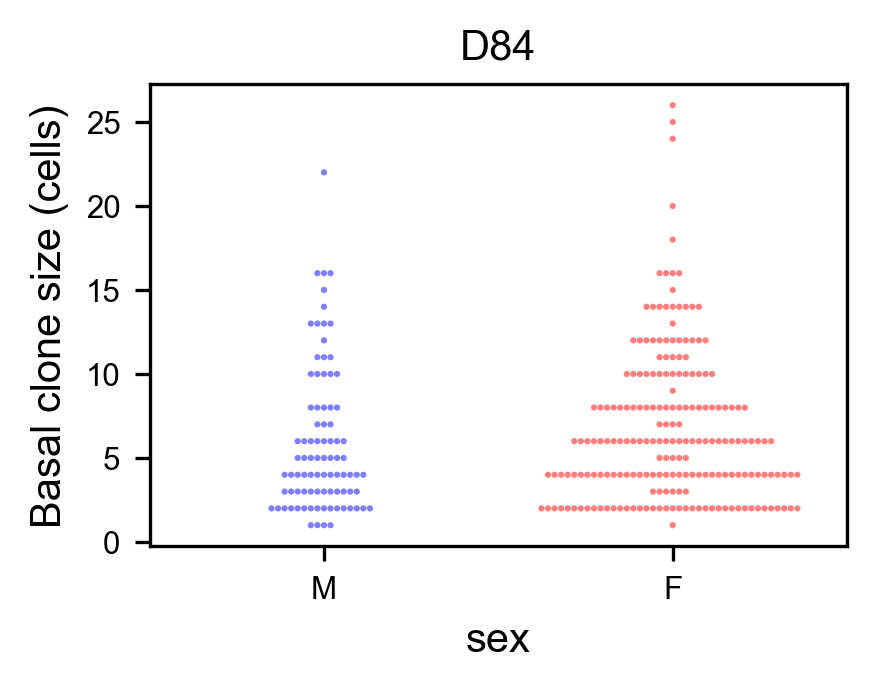

In [9]:
import seaborn as sns

exp_folder = '../../experiment/homeo/'
exp_data = load_object(exp_folder + 'data_ctr.pkl')
livesize = exp_data['livesize']
df = pd.DataFrame(columns = ['sex', 'day', 'bas', 'sup', 'tot'])
times = exp_data['ctrTimeClonesize']

for sex in sexes:
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    livesize = exp_data['livesize']
    for t in range(livesize.shape[1]):
        bas = livesize[:,t,0]
        sup = livesize[:,t,1]
        tot = bas + sup
        sup = sup[bas > 0]
        tot = tot[bas > 0]
        bas = bas[bas > 0]

        df = pd.concat([df, pd.DataFrame({'sex': sex, 'day': int(times[t]), 'bas': bas, 'sup': sup, 'tot': tot})])

palette = ['b', 'r']
plt.figure(figsize=(3, 2), dpi = 300)

sns.swarmplot(data = df[df['day'] == 84], x= 'sex', y = 'bas', palette=palette, size = 1.5, alpha = 0.5)
plt.ylabel('Basal clone size (cells)')
plt.title('D84')


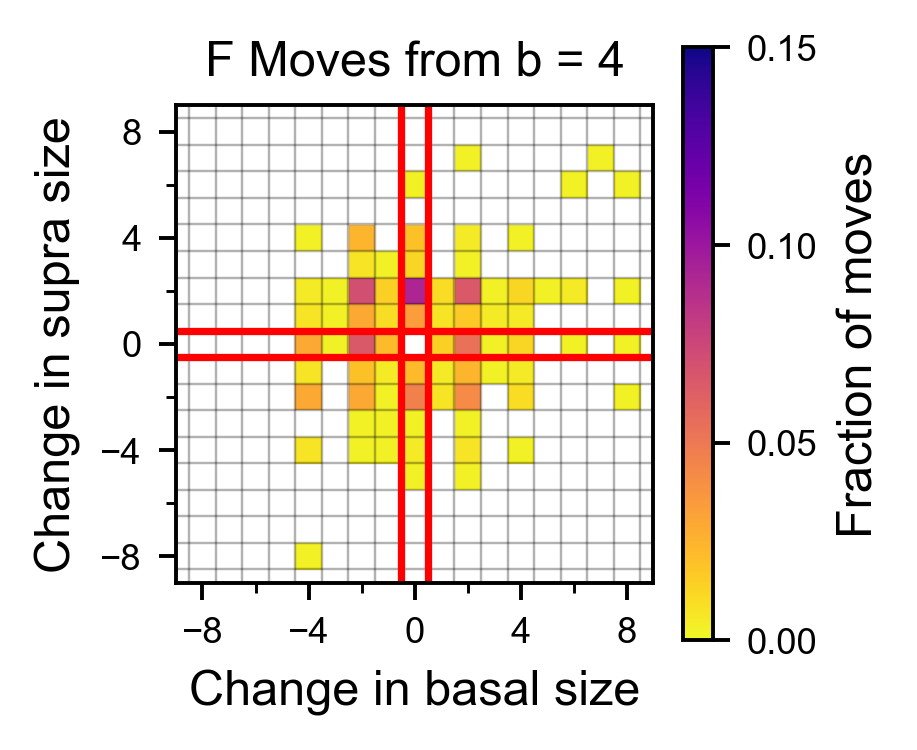

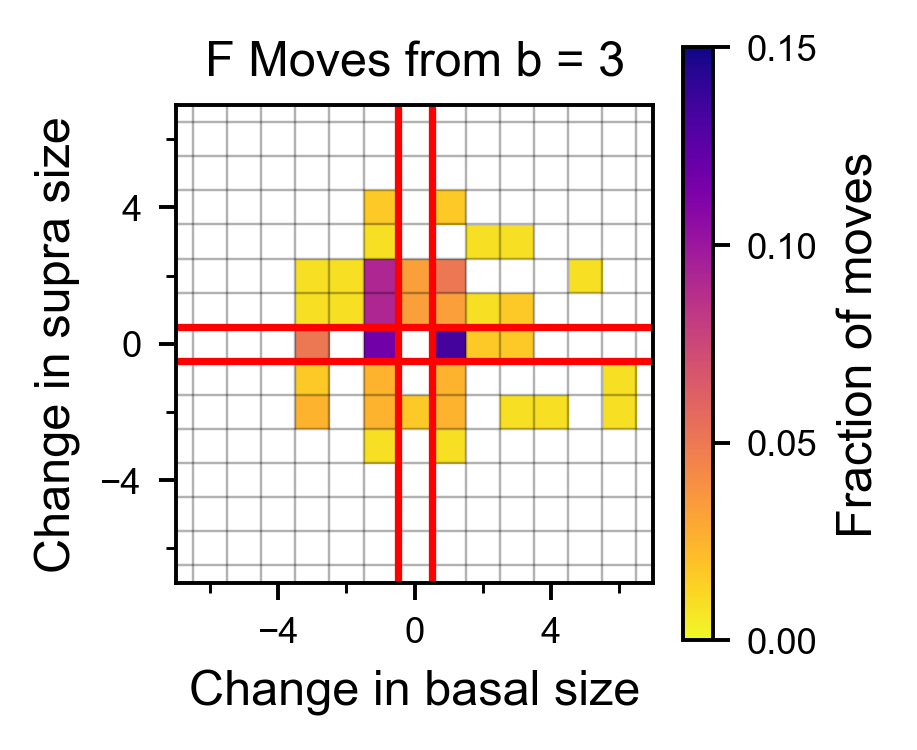

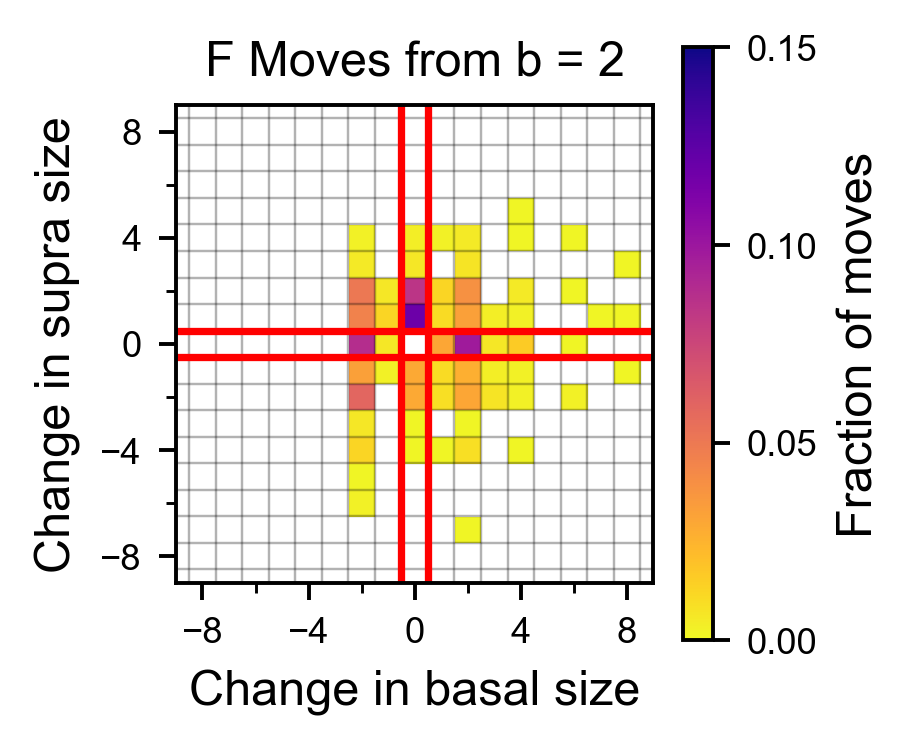

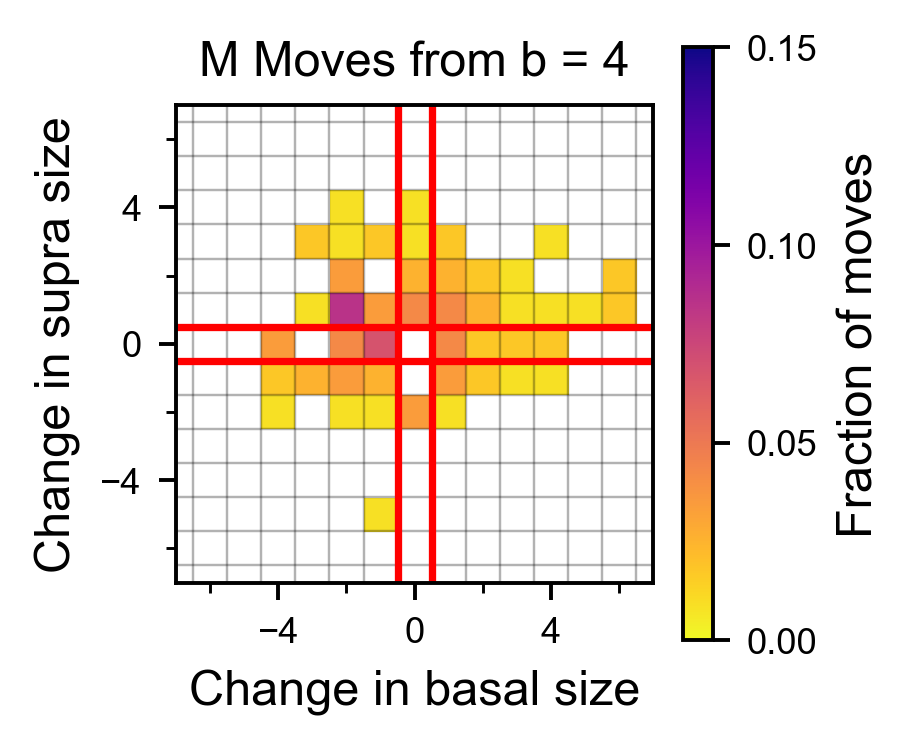

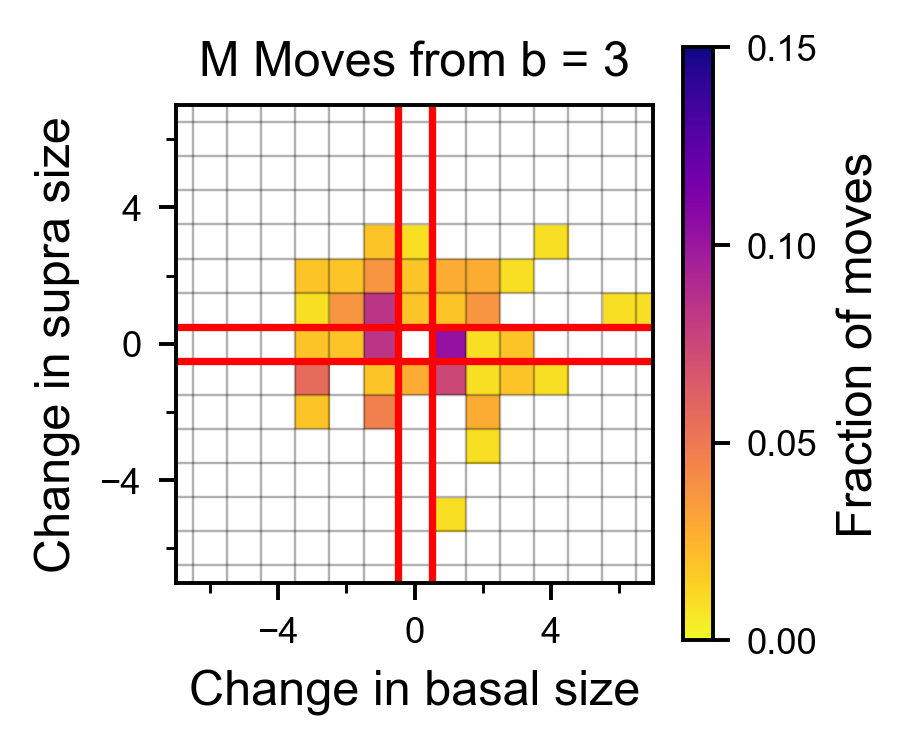

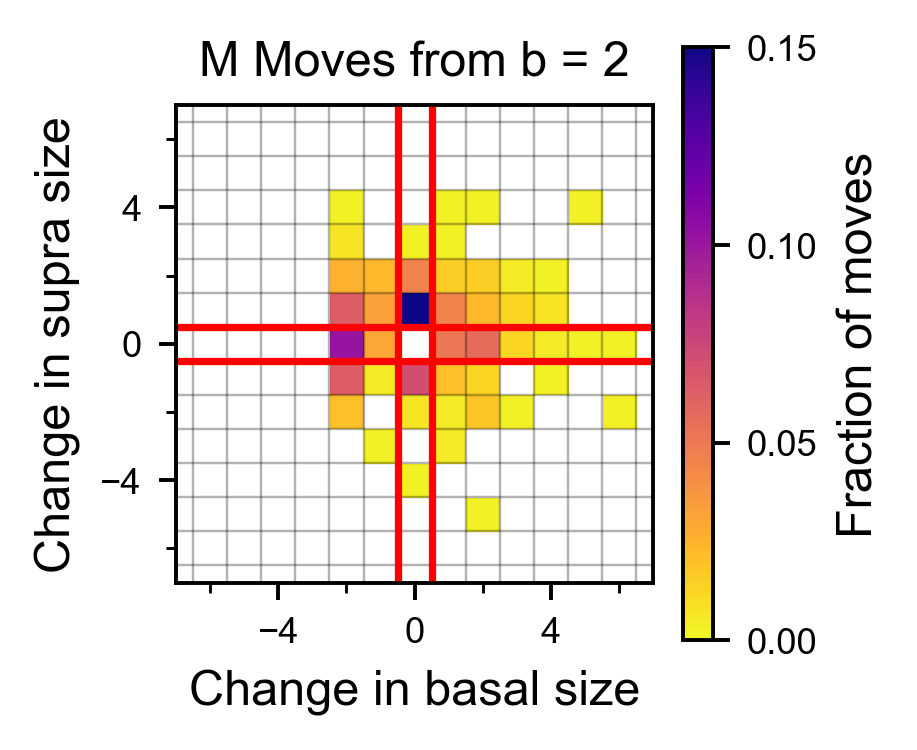

In [10]:

def plot_moves(livesize, init_bas = None, init_sup = None, use_log = False, max_move = 15, normalise = False, 
               tstart = 0, plot = True, tit_prefix = '', vmax = None):
    
    if init_bas is None and init_sup is None:
        tit = 'All moves'
    elif init_bas is not None and init_sup is None:
        tit = 'Moves from b = ' + str(init_bas)
    elif init_bas is None and init_sup is not None:
        tit = 'Moves from b = ' + str(init_sup)
    elif init_bas is not None and init_sup is not None:
        tit = 'Moves from (b,s) = (' + str(init_bas) + ',' + str(init_sup) + ')'
    
    tit = tit_prefix + tit
    
    moves = livesize[:,tstart+1:,0:2] - livesize[:,tstart:-1,0:2] #lag-1 moves, can also do higher order
    ntimes = moves.shape[1]
    moves[np.abs(moves) > 50] = -max_move

    allmoves = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    for t in range(moves.shape[1]):
        for m in range(moves.shape[0]):
            if init_bas is not None and livesize[m,t+tstart,0] != init_bas:
                continue
                
            if init_sup is not None and livesize[m,t+tstart,1] != init_sup:
                continue
                
            allmoves[t,moves[m,t,0], moves[m,t,1]] += 1
        
    allmoves[:,0,0] = 0
    allmoves[:,-max_move,-max_move] = 0

    np.sum(allmoves,0)
    for mb in range(-9,11):
        for ms in range(-9,11):
            if np.sum(allmoves,0)[mb,ms] > 0:
                #print(mb,ms, allmoves[:,mb,ms])
                continue


    allmoves2 = np.zeros((ntimes, max_move*2, max_move*2), dtype = 'int32')
    allmoves2[:,:max_move,:max_move] = allmoves[:,-max_move:,-max_move:]
    allmoves2[:,:max_move,-max_move:] = allmoves[:,-max_move:,:max_move]
    allmoves2[:,-max_move:,:max_move] = allmoves[:,:max_move,-max_move:]
    allmoves2[:,-max_move:,-max_move:] = allmoves[:,:max_move,:max_move]

    if normalise:
        allmoves2 = allmoves2/np.sum(allmoves2)
            
    if plot:
        plt.figure(figsize = (2.2,2.2), dpi = 350)
        if use_log:
            toplot = np.log2(np.sum(allmoves2,0).T)
        else:
            toplot = np.sum(allmoves2,0).T.astype('float')
            toplot[toplot == 0.0] = np.nan
        
        plt.imshow(toplot, extent=[-max_move - 0.5,max_move - 0.5,-max_move - 0.5,max_move - 0.5], 
                   origin='lower', cmap = 'plasma_r', vmin = 0.0, vmax = vmax)
        plt.xlabel('Change in basal size')
        plt.ylabel('Change in supra size')
        if use_log:
            plt.colorbar(label = 'log2(# moves)')
        else:
            plt.colorbar(label = 'Fraction of moves', ticks = [0, 0.05, 0.1, 0.15])
        plt.vlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(-max_move - 0.5,max_move+0.5,1),-max_move,max_move, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.vlines(np.arange(-0.5,1.,1),-max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.hlines(np.arange(-0.5,1,1), -max_move,max_move, color = 'r', linestyles='-', alpha = 1.0)
        plt.ylim([-max_move,max_move])
        plt.xlim([-max_move,max_move])
        plt.xticks(np.arange(-max_move,max_move+1,4))
        plt.yticks(np.arange(-max_move,max_move+1,4))
        plt.xticks(np.arange(-max_move,max_move+1,2), minor = True)
        plt.yticks(np.arange(-max_move,max_move+1,2), minor = True)        
        plt.title(tit)
        #plt.axis('square')
        #plt.show()
    
    return allmoves
    
allmoves = plot_moves(livesize_F, init_bas = 4, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'F ', vmax = 0.15)
plt.xlim([-9,9])
plt.ylim([-9,9])
#plt.savefig(savefolder + 'moveF_4.pdf')
plt.show()


allmoves = plot_moves(livesize_F, init_bas = 3, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'F ', vmax = 0.15)
plt.xlim([-7,7])
plt.ylim([-7,7])
#plt.savefig(savefolder + 'moveF_3.pdf')
plt.show()

allmoves = plot_moves(livesize_F, init_bas = 2, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'F ', vmax = 0.15)
plt.xlim([-9,9])
plt.ylim([-9,9])
#plt.savefig(savefolder + 'moveF_2.pdf')
plt.show()


allmoves = plot_moves(livesize_M, init_bas = 4, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'M ', vmax = 0.15)
plt.xlim([-7,7])
plt.ylim([-7,7])
#plt.savefig(savefolder + 'moveM_4.pdf')
plt.show()


allmoves = plot_moves(livesize_M, init_bas = 3, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'M ', vmax = 0.15)
plt.xlim([-7,7])
plt.ylim([-7,7])
#plt.savefig(savefolder + 'moveM_3.pdf')
plt.show()

allmoves = plot_moves(livesize_M, init_bas = 2, init_sup = None, normalise=True, max_move = 12, 
                      plot = True, tit_prefix = 'M ', vmax = 0.15)
plt.xlim([-7,7])
plt.ylim([-7,7])
#plt.savefig(savefolder + 'moveM_2.pdf')
plt.show()


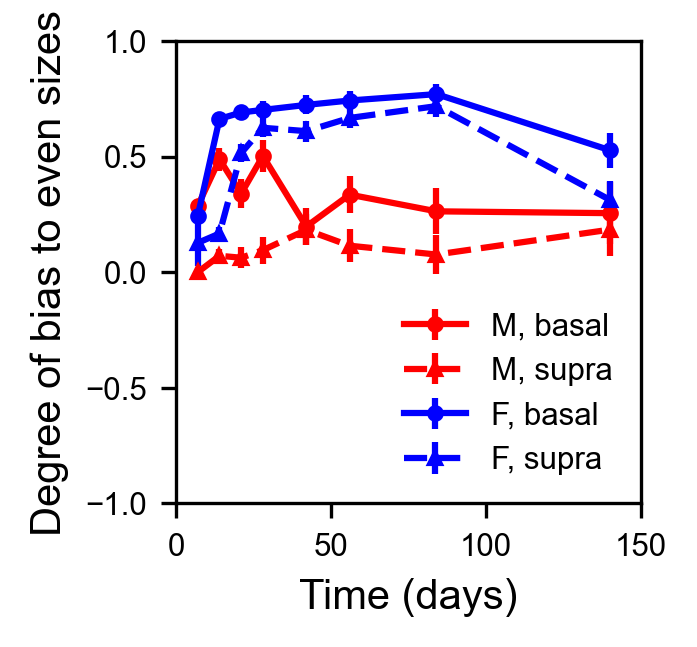

In [11]:
plt.figure(figsize=[2,2], dpi = 300)
for sex in ['M', 'F']:
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.errorbar(clone_anal.tvals, clone_anal.ev_bas_cs, clone_anal.boot('ev_bas_cs'), fmt='o-',  color = col[sex], label = f'{sex}, basal')
    plt.errorbar(clone_anal.tvals, clone_anal.ev_sup_cs, clone_anal.boot('ev_sup_cs'), fmt='^--', color = col[sex], label = f'{sex}, supra')

plt.xlabel('Time (days)')
plt.ylabel('Degree of bias to even sizes')
plt.ylim([-1,1])
plt.xlim([0,150])
plt.legend(frameon = False, loc = 'lower right')
plt.savefig(savefolder + 'even_bias.pdf')
plt.show()

M


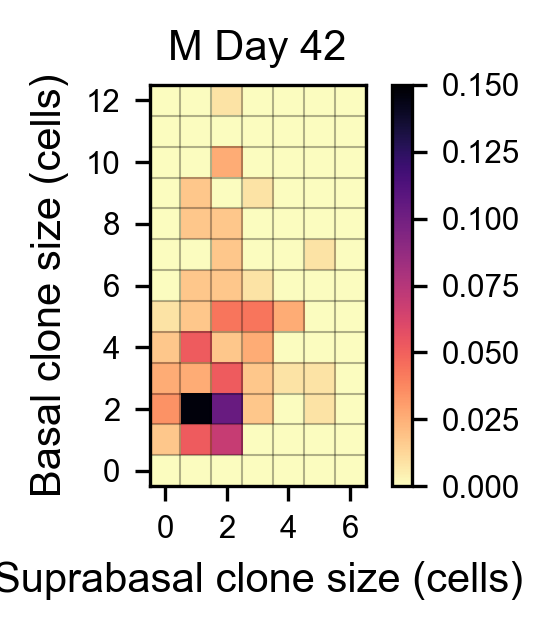

F


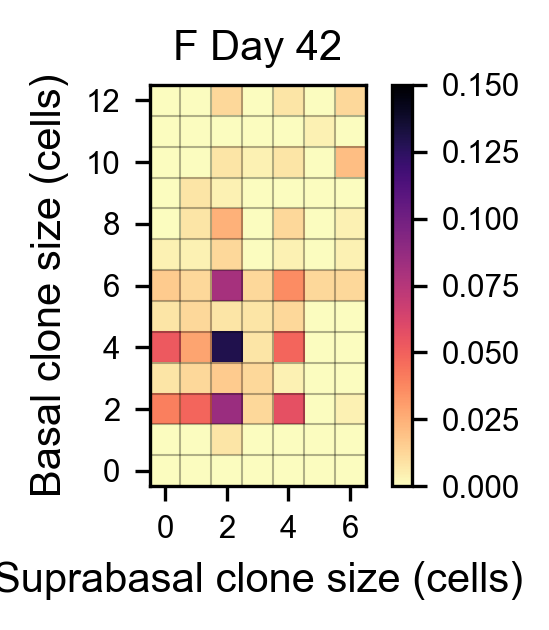

In [12]:
for sex in ['M', 'F']:
    print(sex)
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.figure(figsize=[2.2,2.2], dpi = 300)
    for t in range(4,5):
        #plt.subplot(2, 3, t)
        plt.imshow(clone_anal.joint_bas_sb[t,:,:], origin='lower', cmap = 'magma_r', vmin = 0, vmax = 0.15)
        plt.colorbar()
        plt.xlabel('Suprabasal clone size (cells)')
        plt.ylabel('Basal clone size (cells)')
        plt.vlines(np.arange(0,14) - 0.5, -0.5, 14.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(0,14) - 0.5, -0.5, 14.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.ylim([-0.5, 12.5])
        plt.xlim([-0.5, 6.5])
        plt.xticks(np.arange(0,7,2))
        plt.yticks(np.arange(0,14,2))
        plt.title(f'{sex} Day ' + str(int(clone_anal.tvals[t])))
    plt.tight_layout()
    plt.savefig(f'Figures/Fig1_even_odd/F1_joint_{sex}_D{int(clone_anal.tvals[t])}.pdf')
    plt.show()

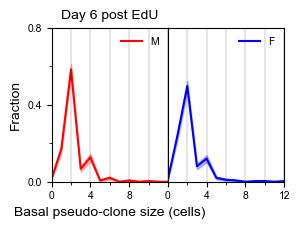

In [13]:
#After 4hr pulse

#Load D6
filename = '../../experiment/homeo/Edu/20241007_EduPseudoClone.xlsx'
D6data = pd.read_excel(filename, sheet_name = 'Feuil1')
D6data = D6data.drop(columns=['Unnamed: 7', 'Unnamed: 8', 'fate_total', 'delta', 'total_cell'])

alldata = pd.concat([D6data], ignore_index=True)
alldata['total'] = alldata['basal'] + alldata['supra']


plt.figure(figsize = (3,2))
i = 1
for sex in ['M', 'F']:
    plt.subplot(1, 2, i)
    i += 1
    subdata = alldata[(alldata['sex'] == sex)]

    histT,bins = np.histogram(subdata['total'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histT, f'{col[sex]}o-', label = sex)
    histB,bins = np.histogram(subdata['basal'], bins=np.arange(20), density=True)
    plt.plot(bins[:-1], histB, f'{col[sex]}-', label = sex)
    plt.fill_between(bins[:-1], histB - np.sqrt(histB*(1-histB)/len(subdata)), histB + np.sqrt(histB*(1-histB)/len(subdata)), alpha = 0.25, color = col[sex])
    histS,bins = np.histogram(subdata['supra'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histS, 'bo-', label = 'supra')
    plt.vlines(np.arange(0,50,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)

    plt.legend(frameon = False)
    plt.xlim([0, 12])
    
    plt.ylim([0, 0.8])    

    if i == 2:
        plt.yticks(np.arange(0, 0.9, 0.4))
        plt.yticks(np.arange(0, 0.9, 0.2), minor = True)   
        plt.xlabel('Basal pseudo-clone size (cells)')  
        plt.ylabel('Fraction')
        plt.title(f'Day 6 post EdU')
        plt.xticks(np.arange(0, 12, 4))        
        plt.xticks(np.arange(0, 13, 2), minor = True)   
    else:
        plt.yticks([])
        plt.xticks(np.arange(0, 13, 4))        
        plt.xticks(np.arange(0, 13, 2), minor = True)           
plt.subplots_adjust(wspace=0.0, hspace=0)
plt.savefig(savefolder + 'F1_basal_D6_post_Edu.pdf')
plt.show()

In [14]:
from scipy.stats import ks_2samp, binomtest, ttest_ind
from scipy.stats import combine_pvalues
import numpy as np

def even_sizes_hypothesis_test(data, alpha=0.05, start_from=1, verbose=False):
    # Calculate the observed proportion of even-sized values
    proportion_even = np.mean(data % 2 == 0)
    
    # Calculate the expected proportion of even-sized values assuming a geometric distribution
    if start_from == 0:
        expected_proportion_even = (1 + np.mean(data)) / (2 * np.mean(data) + 1)
    elif start_from == 1:
        expected_proportion_even = (np.mean(data) - 1)/(2*(np.mean(data)) - 1)
    elif start_from == 2:
        expected_proportion_even = (np.mean(data) - 1) / (2 * np.mean(data) - 3)
    
    # Perform the one-sample proportion test
    result = binomtest(k=np.sum(data % 2 == 0), n=len(data), p=expected_proportion_even, alternative='greater')
    
    if verbose:
        p_value = result.pvalue
        if p_value < alpha:
            print("Reject the null hypothesis (H0): The observed proportion differs significantly from the expected proportion.")
        else:
            print("Do not reject the null hypothesis (H0): The observed proportion does not significantly differ from the expected proportion.")
        
    return proportion_even, expected_proportion_even, result.pvalue

subdata = alldata[(alldata['sex'] == 'M')]
sizes = subdata['basal'].values
sizes = sizes[sizes >= 2]
print(even_sizes_hypothesis_test(sizes, start_from=2))

subdata = alldata[(alldata['sex'] == 'F')]
sizes = subdata['basal'].values
sizes = sizes[sizes >= 2]
even_sizes_hypothesis_test(sizes, start_from=2)

(np.float64(0.9098360655737705), np.float64(0.7276119402985074), np.float64(1.2420272771474563e-12))


(np.float64(0.852017937219731),
 np.float64(0.7045871559633028),
 np.float64(2.131561944537031e-07))

In [15]:
# M vs F difference

from scipy.stats import ks_2samp, binomtest, ttest_ind
from scipy.stats import combine_pvalues
import numpy as np


def hist_to_sample(pdf, n_samples):
    hist_values = n_samples*pdf
    bin_values  = np.arange(0, len(hist_values))
    return np.concatenate([np.repeat(bin_values[i], hist_values[i]) for i in range(len(bin_values))])

def even_sizes_hypothesis_test(data, alpha=0.05, inc0=True, verbose=False):
    # Calculate the observed proportion of even-sized values
    proportion_even = np.mean(data % 2 == 0)
    
    # Calculate the expected proportion of even-sized values assuming a geometric distribution
    if inc0:
        expected_proportion_even = 1 / (1 + np.floor(np.mean(data) / 2))
    else:
        expected_proportion_even = (np.mean(data) - 1)/(2*(np.mean(data)) - 1)
    
    # Perform the one-sample proportion test
    result = binomtest(k=np.sum(data % 2 == 0), n=len(data), p=expected_proportion_even, alternative='greater')
    
    if verbose:
        p_value = result.pvalue
        if p_value < alpha:
            print("Reject the null hypothesis (H0): The observed proportion differs significantly from the expected proportion.")
        else:
            print("Do not reject the null hypothesis (H0): The observed proportion does not significantly differ from the expected proportion.")
        
    return proportion_even, expected_proportion_even, result.pvalue


cpdf = exp_data['ctrpdf']
ks_pval = np.zeros((cpdf.shape[0], 2))
t_test_pval = np.zeros((cpdf.shape[0], 2))

M_ev_pval = np.zeros((cpdf.shape[0], 2))
F_ev_pval = np.zeros((cpdf.shape[0], 2))
M_expected_prop = np.zeros((cpdf.shape[0], 2))
F_expected_prop = np.zeros((cpdf.shape[0], 2))
prop_comparison_pval = np.zeros((cpdf.shape[0], 2))

for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        
        # KS test for distribution differences
        statistic, p_value = ks_2samp(sample1, sample2)
        ks_pval[t,l] = p_value
        
        # One-sided t-test for difference in means (H1: Females > Males)
        t_stat, p_value = ttest_ind(sample2, sample1, equal_var=False, alternative='greater')
        t_test_pval[t,l] = p_value
        
        # Even bias tests
        _, M_expected, M_pval = even_sizes_hypothesis_test(sample1, inc0=(l != 0), verbose=False)
        _, F_expected, F_pval = even_sizes_hypothesis_test(sample2, inc0=(l != 0), verbose=False)
        
        M_ev_pval[t,l] = M_pval
        F_ev_pval[t,l] = F_pval
        M_expected_prop[t,l] = M_expected
        F_expected_prop[t,l] = F_expected
        
        # Test if F_expected > M_expected (one-sided)
        # For this comparison, we'll use a bootstrap or permutation test
        # since we're comparing expected proportions
        n_bootstrap = 10000
        diff_observed = F_expected - M_expected
        
        # Create combined sample for permutation
        combined = np.concatenate([sample1, sample2])
        n1 = len(sample1)
        n2 = len(sample2)
        
        diffs = np.zeros(n_bootstrap)
        
        for i in range(n_bootstrap):
            np.random.shuffle(combined)
            boot_sample1 = combined[:n1]
            boot_sample2 = combined[n1:]
            
            # Calculate expected proportions for bootstrap samples
            if l != 0:
                boot_M_expected = 1 / (1 + np.floor(np.mean(boot_sample1) / 2))
                boot_F_expected = 1 / (1 + np.floor(np.mean(boot_sample2) / 2))
            else:
                boot_M_expected = (np.mean(boot_sample1) - 1)/(2*(np.mean(boot_sample1)) - 1)
                boot_F_expected = (np.mean(boot_sample2) - 1)/(2*(np.mean(boot_sample2)) - 1)
            
            diffs[i] = boot_F_expected - boot_M_expected
        
        # Calculate p-value (proportion of bootstrap differences >= observed difference)
        # For one-sided test: F_expected > M_expected
        prop_comparison_pval[t,l] = np.mean(diffs >= diff_observed)


# Analyze by layer (combining across time points)
tol = 0.05


# Combining p-values by layer (across time)
layers = ["Basal", "Suprabasal"]

even_bias_pvals = np.zeros((2, 2, 8))

print("\nStatistical Tests by layer:")

for l in range(2):
    print(f"\n--- {layers[l]} ---")
    
    # T-test for mean difference (F > M)
    t_layer_pvals = t_test_pval[:, l]
    combined_t_layer = combine_pvalues(t_layer_pvals, method='fisher')[1]
    print(f"One-sided t-test for means (F > M): p-values = {t_layer_pvals}, Combined p = {combined_t_layer:.6f}")
    
    # KS test for distribution difference
    ks_layer_pvals = ks_pval[:, l]
    combined_ks_layer = combine_pvalues(ks_layer_pvals, method='fisher')[1]
    print(f"KS test for distributions: p-values = {ks_layer_pvals}, Combined p = {combined_ks_layer:.6f}")
    
    # Even bias test M
    M_ev_layer_pvals = M_ev_pval[:, l]
    combined_M_ev_layer = combine_pvalues(M_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test M: p-values = {M_ev_layer_pvals}, Combined p = {combined_M_ev_layer:.6f}")
    
    # Even bias test F
    F_ev_layer_pvals = F_ev_pval[:, l]
    combined_F_ev_layer = combine_pvalues(F_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test F: p-values = {F_ev_layer_pvals}, Combined p = {combined_F_ev_layer:.6f}")
    
    # Expected proportion comparison (F > M)
    prop_comp_layer_pvals = prop_comparison_pval[:, l]
    combined_prop_comp_layer = combine_pvalues(prop_comp_layer_pvals, method='fisher')[1]
    print(f"Expected proportion comparison (F > M): p-values = {prop_comp_layer_pvals}, Combined p = {combined_prop_comp_layer:.6f}")

# Print statistics on means for context
print("Mean comparison statistics:")
for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        mean1 = np.mean(sample1)  # Male mean
        mean2 = np.mean(sample2)  # Female mean
        print(f"Time {t}, Layer {l}: M mean = {mean1:.3f}, F mean = {mean2:.3f}, Diff (F-M) = {mean2-mean1:.3f}")

# Expected proportion comparison
print("\nExpected proportion of even-sized values comparison (F > M):")
for t in range(cpdf.shape[0]):
    for l in range(2):
        print(f"Time {t}, Layer {layers[l]}: M expected = {M_expected_prop[t,l]:.3f}, F expected = {F_expected_prop[t,l]:.3f}, " +
              f"Diff (F-M) = {F_expected_prop[t,l] - M_expected_prop[t,l]:.3f}, p-value = {prop_comparison_pval[t,l]:.6f}")



Statistical Tests by layer:

--- Basal ---
One-sided t-test for means (F > M): p-values = [6.84019952e-01 3.15129283e-04 1.07149825e-01 8.54657426e-03
 4.85045053e-06 5.24789855e-07 7.64631120e-02 2.39456891e-04], Combined p = 0.000000
KS test for distributions: p-values = [9.04487513e-01 1.35799497e-02 4.02781399e-01 2.83809134e-03
 1.56174821e-05 1.49429297e-05 1.96340339e-01 4.97235062e-02], Combined p = 0.000000
Even bias test M: p-values = [2.09728586e-20 1.37761063e-20 1.17533976e-07 6.73408632e-12
 8.81985699e-03 9.11856594e-06 5.13204695e-03 5.71241723e-02], Combined p = 0.000000
Even bias test F: p-values = [9.35449842e-29 2.07449125e-70 9.04658140e-59 2.89850412e-47
 9.27260788e-39 2.57165199e-37 2.82043348e-35 4.84758603e-10], Combined p = 0.000000
Expected proportion comparison (F > M): p-values = [7.007e-01 7.000e-04 1.177e-01 9.700e-03 0.000e+00 0.000e+00 8.230e-02
 1.500e-03], Combined p = 0.000000

--- Suprabasal ---
One-sided t-test for means (F > M): p-values = [3.69

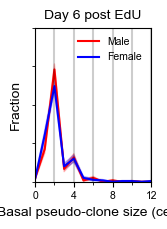

In [16]:
#After 4hr pulse

#Load D6
filename = '../../experiment/homeo/Edu/20241007_EduPseudoClone.xlsx'
D6data = pd.read_excel(filename, sheet_name = 'Feuil1')
D6data = D6data.drop(columns=['Unnamed: 7', 'Unnamed: 8', 'fate_total', 'delta', 'total_cell'])

alldata = pd.concat([D6data], ignore_index=True)
alldata['total'] = alldata['basal'] + alldata['supra']

fullsex = {'M': 'Male', 'F': 'Female'}

plt.figure(figsize = (1.5,2))
i = 1
for sex in ['M', 'F']:
    #plt.subplot(1, 2, i)
    i += 1
    subdata = alldata[(alldata['sex'] == sex)]

    histT,bins = np.histogram(subdata['total'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histT, f'{col[sex]}o-', label = sex)
    histB,bins = np.histogram(subdata['basal'], bins=np.arange(20), density=True)
    plt.plot(bins[:-1], histB, f'{col[sex]}-', label = fullsex[sex])
    plt.fill_between(bins[:-1], histB - np.sqrt(histB*(1-histB)/len(subdata)), histB + np.sqrt(histB*(1-histB)/len(subdata)), alpha = 0.25, color = col[sex])
    histS,bins = np.histogram(subdata['supra'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histS, 'bo-', label = 'supra')
    plt.vlines(np.arange(0,50,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)

    plt.legend(frameon = False)
    plt.xlim([0, 12])
    
    plt.ylim([0, 0.8])    

    if i == 2:
        plt.yticks(np.arange(0, 0.9, 0.4))
        plt.yticks(np.arange(0, 0.9, 0.2), minor = True)   
        plt.xlabel('Basal pseudo-clone size (cells)')  
        plt.ylabel('Fraction')
        plt.title(f'Day 6 post EdU')
        plt.xticks(np.arange(0, 12, 4))        
        plt.xticks(np.arange(0, 13, 2), minor = True)   
    else:
        plt.yticks([])
        plt.xticks(np.arange(0, 13, 4))        
        plt.xticks(np.arange(0, 13, 2), minor = True)           
plt.subplots_adjust(wspace=0.0, hspace=0)
plt.savefig(savefolder + 'F1_basal_D6_post_Edu.pdf', bbox_inches = 'tight')
plt.show()

In [17]:
# M vs F difference
from scipy.stats import ks_2samp, binomtest, ttest_ind
from scipy.stats import combine_pvalues
import numpy as np


def hist_to_sample(pdf, n_samples):
    hist_values = n_samples*pdf
    bin_values  = np.arange(0, len(hist_values))
    return np.concatenate([np.repeat(bin_values[i], hist_values[i]) for i in range(len(bin_values))])

def even_sizes_hypothesis_test(data, alpha=0.05, inc0=True, verbose=False):
    # Calculate the observed proportion of even-sized values
    proportion_even = np.mean(data % 2 == 0)
    
    # Calculate the expected proportion of even-sized values assuming a geometric distribution
    if inc0:
        expected_proportion_even = 1 / (1 + np.floor(np.mean(data) / 2))
    else:
        expected_proportion_even = (np.mean(data) - 1)/(2*(np.mean(data)) - 1)
    
    # Perform the one-sample proportion test
    result = binomtest(k=np.sum(data % 2 == 0), n=len(data), p=expected_proportion_even, alternative='greater')
    
    if verbose:
        p_value = result.pvalue
        if p_value < alpha:
            print("Reject the null hypothesis (H0): The observed proportion differs significantly from the expected proportion.")
        else:
            print("Do not reject the null hypothesis (H0): The observed proportion does not significantly differ from the expected proportion.")
        
    return proportion_even, expected_proportion_even, result.pvalue


cpdf = exp_data['ctrpdf']
ks_pval = np.zeros((cpdf.shape[0], 2))
t_test_pval = np.zeros((cpdf.shape[0], 2))

M_ev_pval = np.zeros((cpdf.shape[0], 2))
F_ev_pval = np.zeros((cpdf.shape[0], 2))
M_expected_prop = np.zeros((cpdf.shape[0], 2))
F_expected_prop = np.zeros((cpdf.shape[0], 2))
prop_comparison_pval = np.zeros((cpdf.shape[0], 2))

for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        
        # KS test for distribution differences
        statistic, p_value = ks_2samp(sample1, sample2)
        ks_pval[t,l] = p_value
        
        # One-sided t-test for difference in means (H1: Females > Males)
        t_stat, p_value = ttest_ind(sample2, sample1, equal_var=False, alternative='greater')
        t_test_pval[t,l] = p_value
        
        # Even bias tests
        _, M_expected, M_pval = even_sizes_hypothesis_test(sample1, inc0=(l != 0), verbose=False)
        _, F_expected, F_pval = even_sizes_hypothesis_test(sample2, inc0=(l != 0), verbose=False)
        
        M_ev_pval[t,l] = M_pval
        F_ev_pval[t,l] = F_pval
        M_expected_prop[t,l] = M_expected
        F_expected_prop[t,l] = F_expected
        
        # Test if F_expected > M_expected (one-sided)
        # For this comparison, we'll use a bootstrap or permutation test
        # since we're comparing expected proportions
        n_bootstrap = 10000
        diff_observed = F_expected - M_expected
        
        # Create combined sample for permutation
        combined = np.concatenate([sample1, sample2])
        n1 = len(sample1)
        n2 = len(sample2)
        
        diffs = np.zeros(n_bootstrap)
        
        for i in range(n_bootstrap):
            np.random.shuffle(combined)
            boot_sample1 = combined[:n1]
            boot_sample2 = combined[n1:]
            
            # Calculate expected proportions for bootstrap samples
            if l != 0:
                boot_M_expected = 1 / (1 + np.floor(np.mean(boot_sample1) / 2))
                boot_F_expected = 1 / (1 + np.floor(np.mean(boot_sample2) / 2))
            else:
                boot_M_expected = (np.mean(boot_sample1) - 1)/(2*(np.mean(boot_sample1)) - 1)
                boot_F_expected = (np.mean(boot_sample2) - 1)/(2*(np.mean(boot_sample2)) - 1)
            
            diffs[i] = boot_F_expected - boot_M_expected
        
        # Calculate p-value (proportion of bootstrap differences >= observed difference)
        # For one-sided test: F_expected > M_expected
        prop_comparison_pval[t,l] = np.mean(diffs >= diff_observed)


# Analyze by layer (combining across time points)
tol = 0.05


# Combining p-values by layer (across time)
layers = ["Basal", "Suprabasal"]

even_bias_pvals = np.zeros((2, 2, 8))

print("\nStatistical Tests by layer:")

for l in range(2):
    print(f"\n--- {layers[l]} ---")
    
    # T-test for mean difference (F > M)
    t_layer_pvals = t_test_pval[:, l]
    combined_t_layer = combine_pvalues(t_layer_pvals, method='fisher')[1]
    print(f"One-sided t-test for means (F > M): p-values = {t_layer_pvals}, Combined p = {combined_t_layer:.6f}")
    
    # KS test for distribution difference
    ks_layer_pvals = ks_pval[:, l]
    combined_ks_layer = combine_pvalues(ks_layer_pvals, method='fisher')[1]
    print(f"KS test for distributions: p-values = {ks_layer_pvals}, Combined p = {combined_ks_layer:.6f}")
    
    # Even bias test M
    M_ev_layer_pvals = M_ev_pval[:, l]
    combined_M_ev_layer = combine_pvalues(M_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test M: p-values = {M_ev_layer_pvals}, Combined p = {combined_M_ev_layer:.6f}")
    
    # Even bias test F
    F_ev_layer_pvals = F_ev_pval[:, l]
    combined_F_ev_layer = combine_pvalues(F_ev_layer_pvals, method='fisher')[1]
    print(f"Even bias test F: p-values = {F_ev_layer_pvals}, Combined p = {combined_F_ev_layer:.6f}")
    
    # Expected proportion comparison (F > M)
    prop_comp_layer_pvals = prop_comparison_pval[:, l]
    combined_prop_comp_layer = combine_pvalues(prop_comp_layer_pvals, method='fisher')[1]
    print(f"Expected proportion comparison (F > M): p-values = {prop_comp_layer_pvals}, Combined p = {combined_prop_comp_layer:.6f}")

# Print statistics on means for context
print("Mean comparison statistics:")
for t in range(cpdf.shape[0]):
    for l in range(2):
        sample1 = hist_to_sample(exp_data_M['ctrpdf'][t,l,:], exp_data_M['ctrNsamples'][t])  # Males
        sample2 = hist_to_sample(exp_data_F['ctrpdf'][t,l,:], exp_data_F['ctrNsamples'][t])  # Females
        mean1 = np.mean(sample1)  # Male mean
        mean2 = np.mean(sample2)  # Female mean
        print(f"Time {t}, Layer {l}: M mean = {mean1:.3f}, F mean = {mean2:.3f}, Diff (F-M) = {mean2-mean1:.3f}")

# Expected proportion comparison
print("\nExpected proportion of even-sized values comparison (F > M):")
for t in range(cpdf.shape[0]):
    for l in range(2):
        print(f"Time {t}, Layer {layers[l]}: M expected = {M_expected_prop[t,l]:.3f}, F expected = {F_expected_prop[t,l]:.3f}, " +
              f"Diff (F-M) = {F_expected_prop[t,l] - M_expected_prop[t,l]:.3f}, p-value = {prop_comparison_pval[t,l]:.6f}")



Statistical Tests by layer:

--- Basal ---
One-sided t-test for means (F > M): p-values = [6.84019952e-01 3.15129283e-04 1.07149825e-01 8.54657426e-03
 4.85045053e-06 5.24789855e-07 7.64631120e-02 2.39456891e-04], Combined p = 0.000000
KS test for distributions: p-values = [9.04487513e-01 1.35799497e-02 4.02781399e-01 2.83809134e-03
 1.56174821e-05 1.49429297e-05 1.96340339e-01 4.97235062e-02], Combined p = 0.000000
Even bias test M: p-values = [2.09728586e-20 1.37761063e-20 1.17533976e-07 6.73408632e-12
 8.81985699e-03 9.11856594e-06 5.13204695e-03 5.71241723e-02], Combined p = 0.000000
Even bias test F: p-values = [9.35449842e-29 2.07449125e-70 9.04658140e-59 2.89850412e-47
 9.27260788e-39 2.57165199e-37 2.82043348e-35 4.84758603e-10], Combined p = 0.000000
Expected proportion comparison (F > M): p-values = [7.012e-01 6.000e-04 1.133e-01 8.600e-03 0.000e+00 0.000e+00 8.390e-02
 1.500e-03], Combined p = 0.000000

--- Suprabasal ---
One-sided t-test for means (F > M): p-values = [3.69

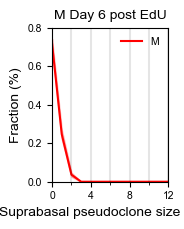

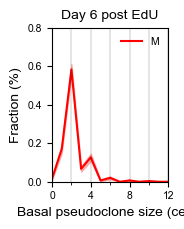

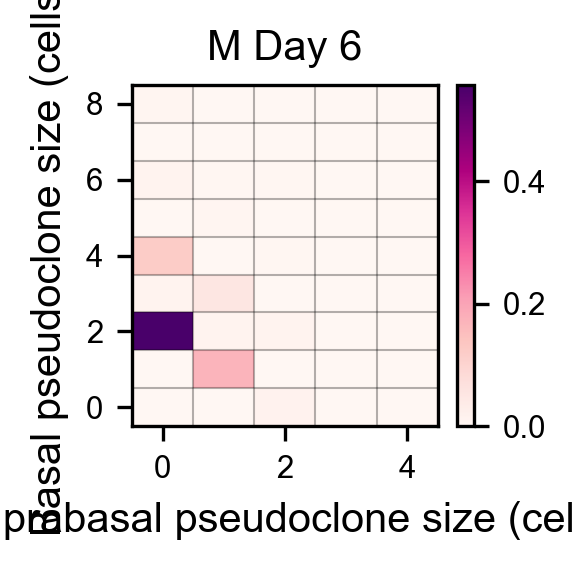

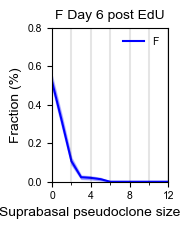

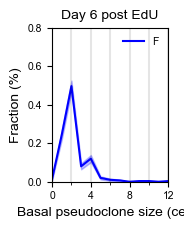

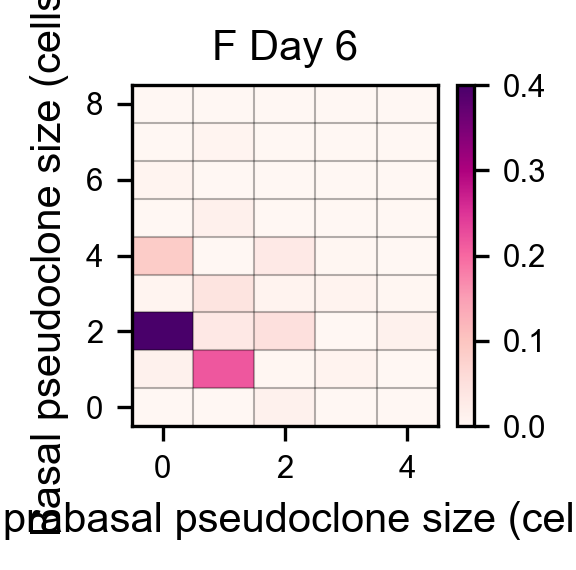

In [18]:
#After 4hr pulse

#Load D6
filename = '../../experiment/homeo/Edu/20241007_EduPseudoClone.xlsx'
D6data = pd.read_excel(filename, sheet_name = 'Feuil1')
D6data = D6data.drop(columns=['Unnamed: 7', 'Unnamed: 8', 'fate_total', 'delta', 'total_cell'])

alldata = pd.concat([D6data], ignore_index=True)
alldata['total'] = alldata['basal'] + alldata['supra']


for sex in ['M', 'F']:
    subdata = alldata[(alldata['sex'] == sex)]
    plt.figure(figsize = (1.5,2))
    histT,bins = np.histogram(subdata['total'], bins=np.arange(20), density=True)
    histB,bins = np.histogram(subdata['basal'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histB, 'ro-', label = 'basal')
    histS,bins = np.histogram(subdata['supra'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histS, 'bo-', label = 'supra')
    plt.plot(bins[:-1], histS, f'{col[sex]}-', label = sex)    
    plt.vlines(np.arange(0,50,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)
    plt.fill_between(bins[:-1], histS - np.sqrt(histS*(1-histS)/len(subdata)), histS + np.sqrt(histS*(1-histS)/len(subdata)), alpha = 0.25, color = col[sex])

    plt.legend(frameon = False)
    plt.xlabel('Suprabasal pseudoclone size (cells)')
    plt.ylabel('Fraction (%)')
    plt.title(f'{sex} Day 6 post EdU')
    plt.xlim([0, 12])
    plt.ylim([0, 0.8])   
    plt.xticks(np.arange(0, 13, 4))        
    plt.yticks(np.arange(0, 0.9, 0.2))
    plt.xticks(np.arange(0, 13, 2), minor = True)        
    plt.yticks(np.arange(0.85, 0.05), minor = True)        
    plt.savefig(savefolder + 'F1_supra_D6_post_Edu_' + sex + '.pdf')
    plt.show()

    subdata = alldata[(alldata['sex'] == sex)]
    plt.figure(figsize = (1.5,2))
    histT,bins = np.histogram(subdata['total'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histT, f'{col[sex]}o-', label = sex)
    histB,bins = np.histogram(subdata['basal'], bins=np.arange(20), density=True)
    plt.plot(bins[:-1], histB, f'{col[sex]}-', label = sex)
    plt.fill_between(bins[:-1], histB - np.sqrt(histB*(1-histB)/len(subdata)), histB + np.sqrt(histB*(1-histB)/len(subdata)), alpha = 0.25, color = col[sex])
    histS,bins = np.histogram(subdata['supra'], bins=np.arange(20), density=True)
    #plt.plot(bins[:-1], histS, 'bo-', label = 'supra')
    plt.vlines(np.arange(0,50,2), 0, 1, color = 'k', linestyle = '-', alpha = 0.1)

    plt.legend(frameon = False)
    plt.xlabel('Basal pseudoclone size (cells)')
    plt.ylabel('Fraction (%)')
    plt.title(f'Day 6 post EdU')
    plt.xlim([0, 12])
    plt.ylim([0, 0.8])   
    plt.xticks(np.arange(0, 13, 4))        
    plt.yticks(np.arange(0, 0.9, 0.2))
    plt.xticks(np.arange(0, 13, 2), minor = True)        
    plt.yticks(np.arange(0.85, 0.05), minor = True)     
    plt.savefig(savefolder + 'F1_basal_D6_post_Edu_' + sex + '.pdf')
    plt.show()
    

    plt.figure(figsize=[2,2], dpi = 300)
    plt.hist2d(subdata['supra'], subdata['basal'], bins = [np.arange(20) - 0.5, 
                        np.arange(20) - 0.5], cmap = 'RdPu', density= True) #RdPu, magma_r
    plt.colorbar()
    plt.vlines(np.arange(0,20) - 0.5, -0.5, 20.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
    plt.hlines(np.arange(0,20) - 0.5, -0.5, 20.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
    plt.xticks(np.arange(0,20,2))
    plt.yticks(np.arange(0,20,2))
    plt.ylim([-0.5, 8.5])
    plt.xlim([-0.5, 4.5])    
    plt.ylabel('Basal pseudoclone size (cells)')
    plt.xlabel('Suprabasal pseudoclone size (cells)')
    plt.title(f'{sex} Day 6')
    plt.tight_layout()
    plt.savefig(f'Figures/Fig1_even_odd/F1_Edu_{sex}_joint_distribution.pdf')
    plt.show() 

M


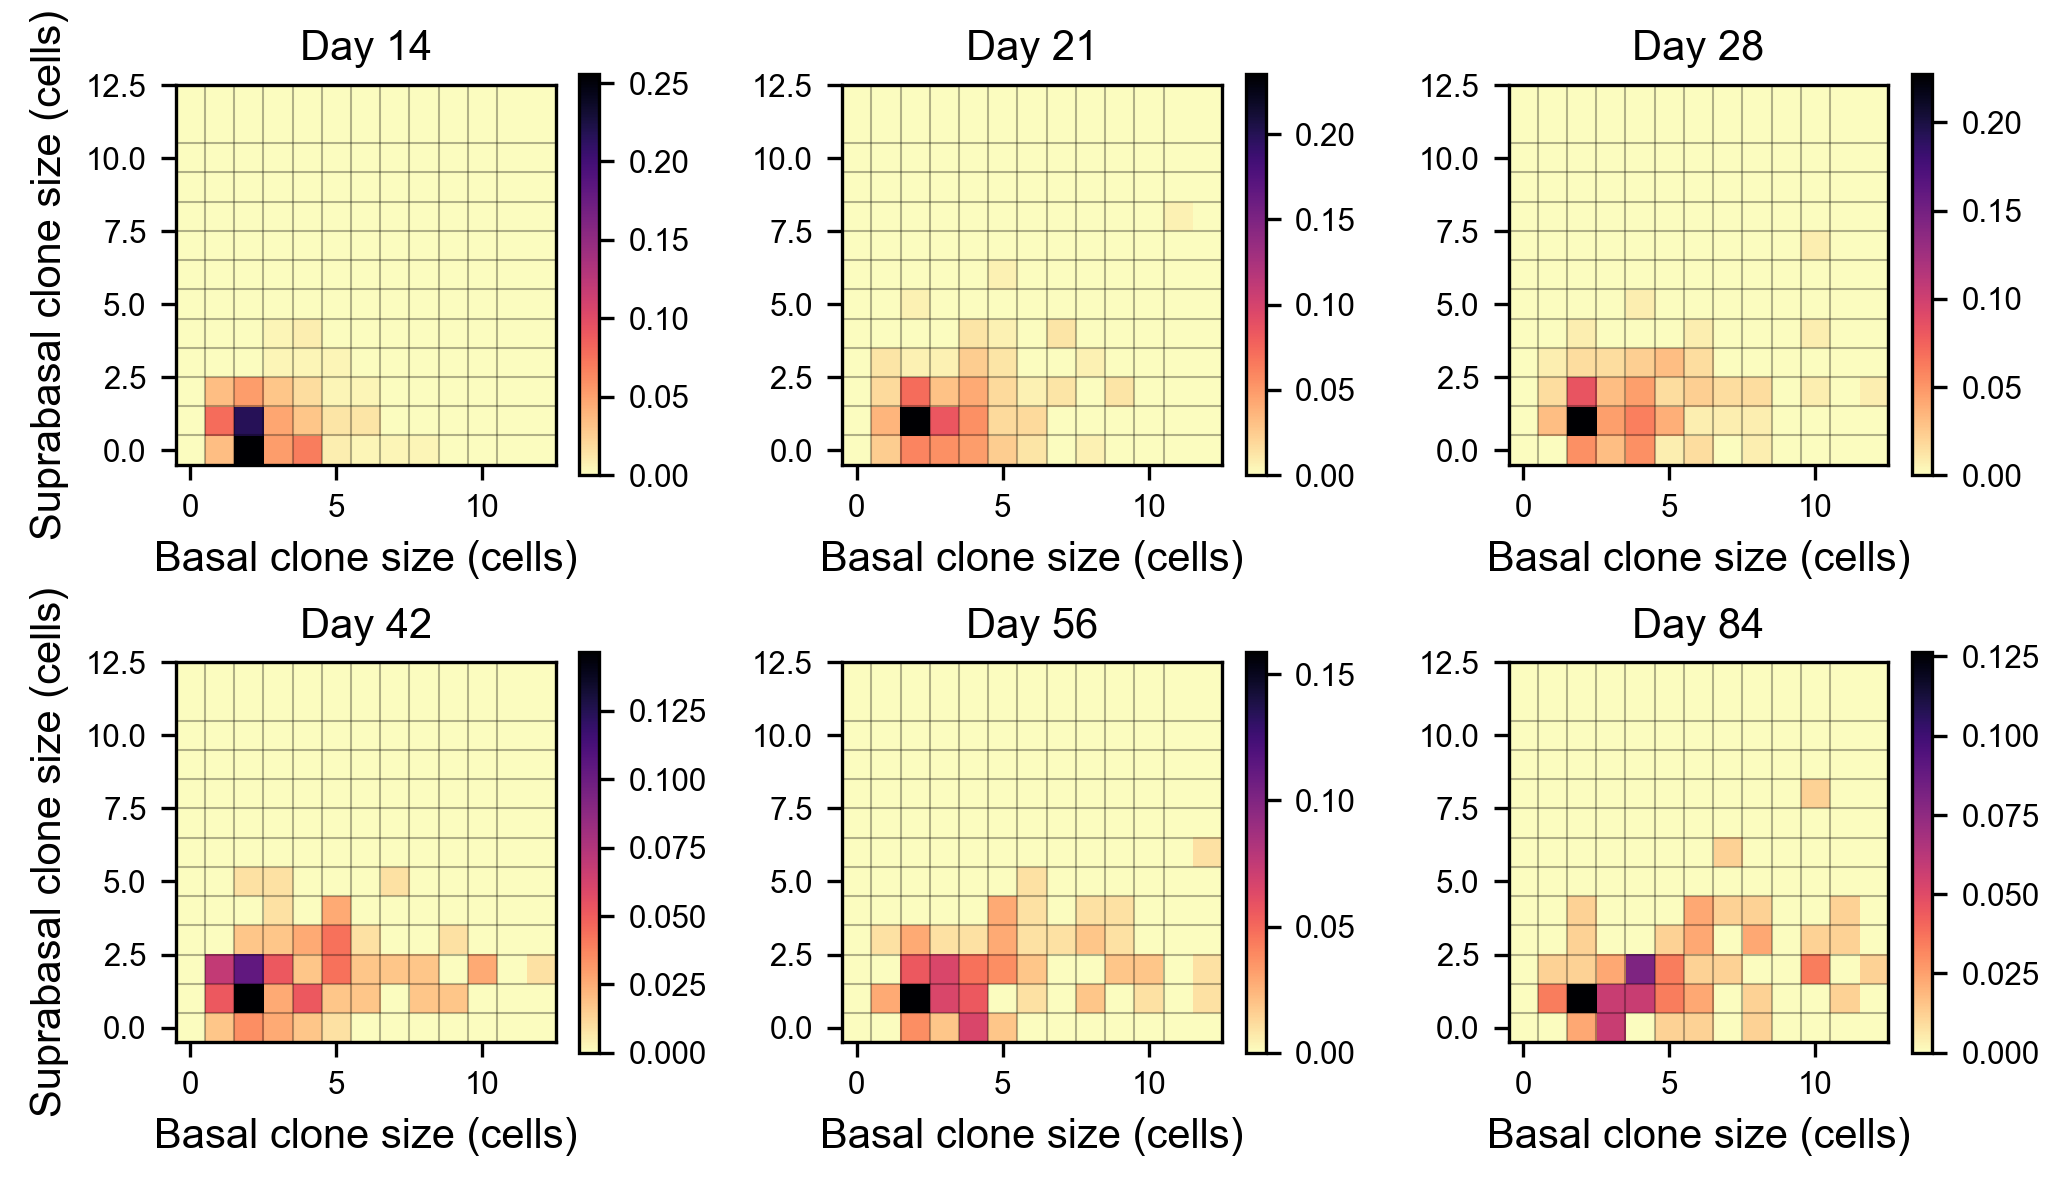

F


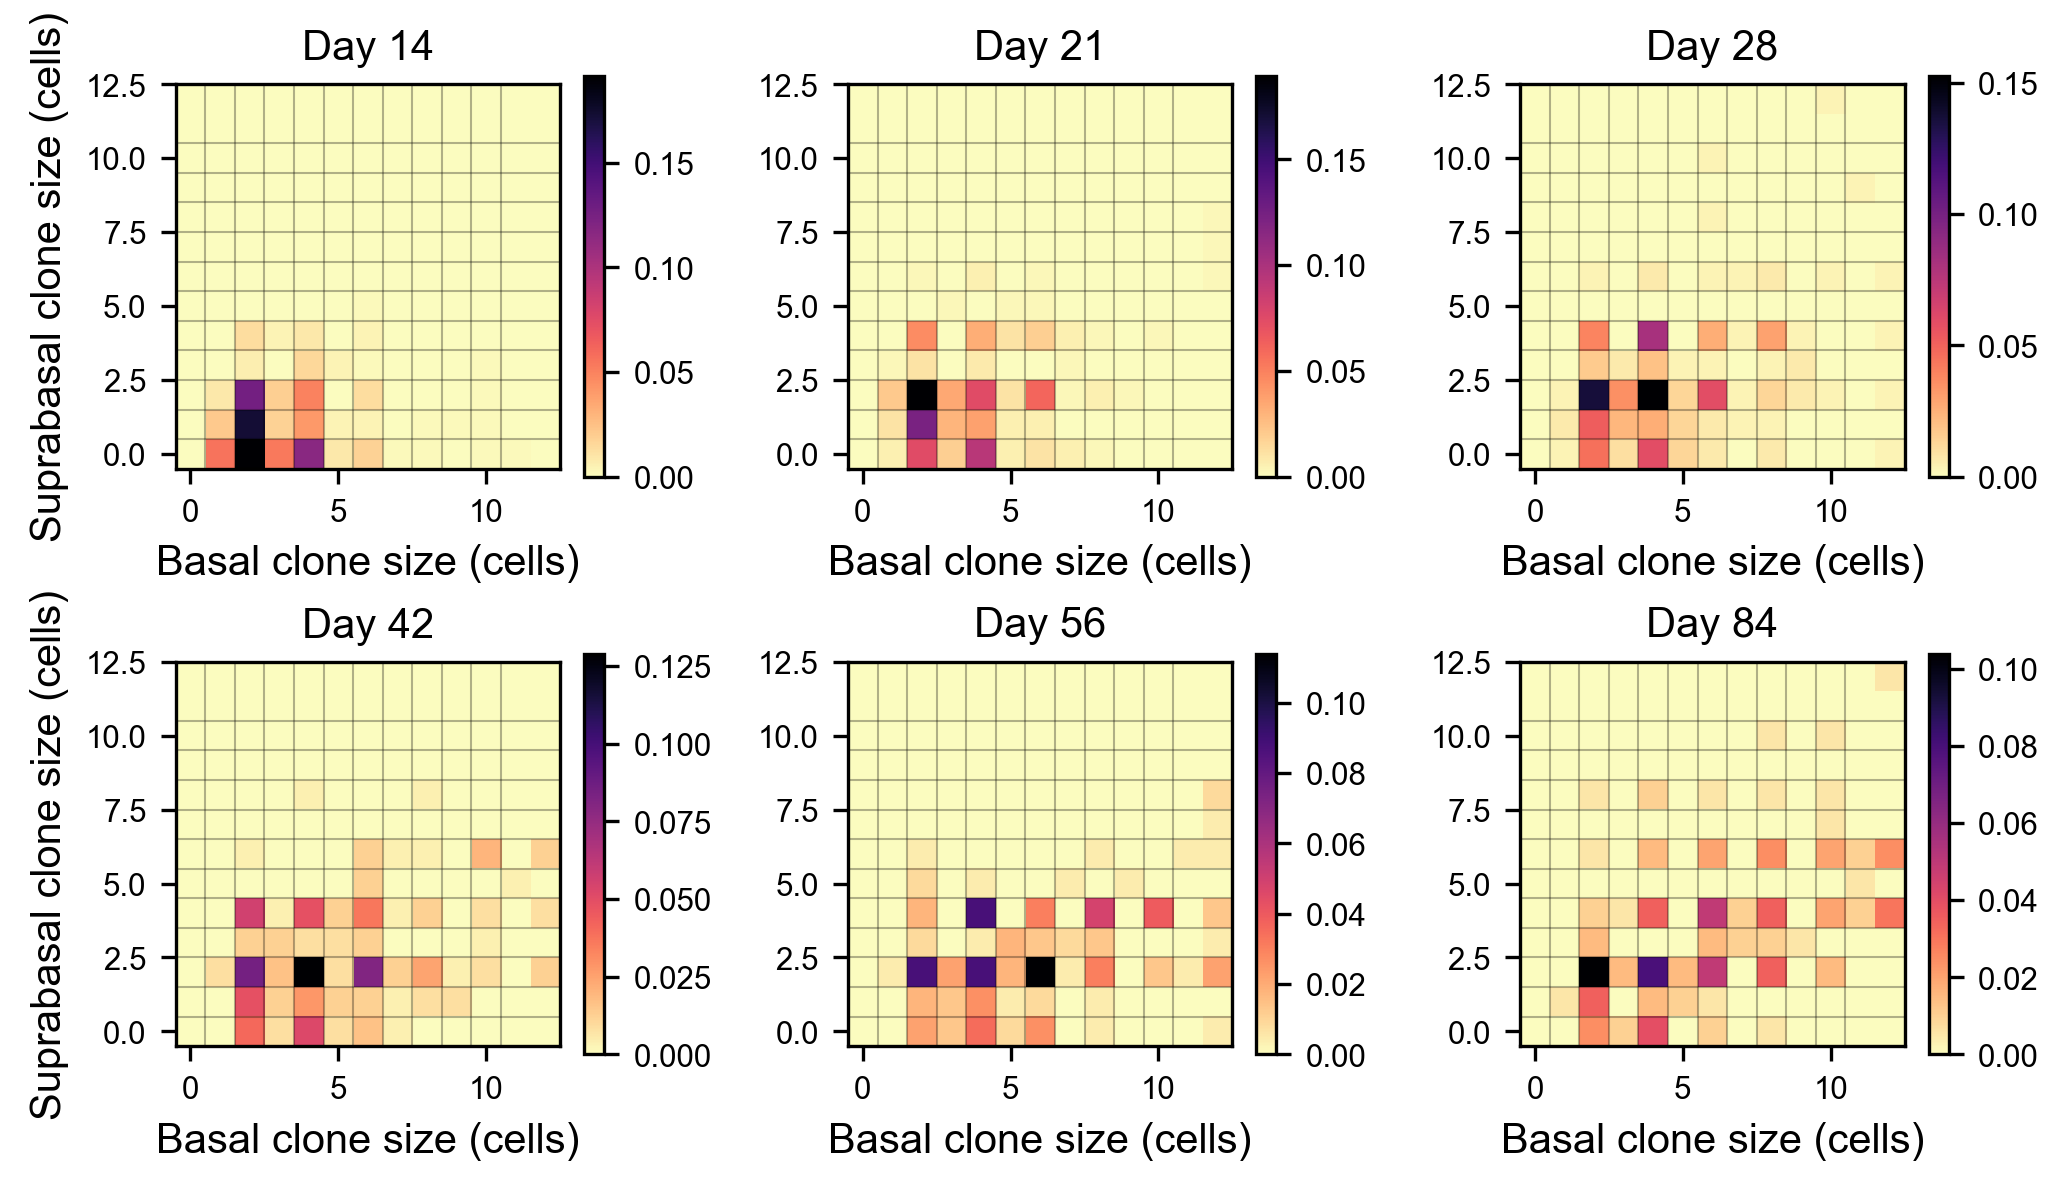

M30


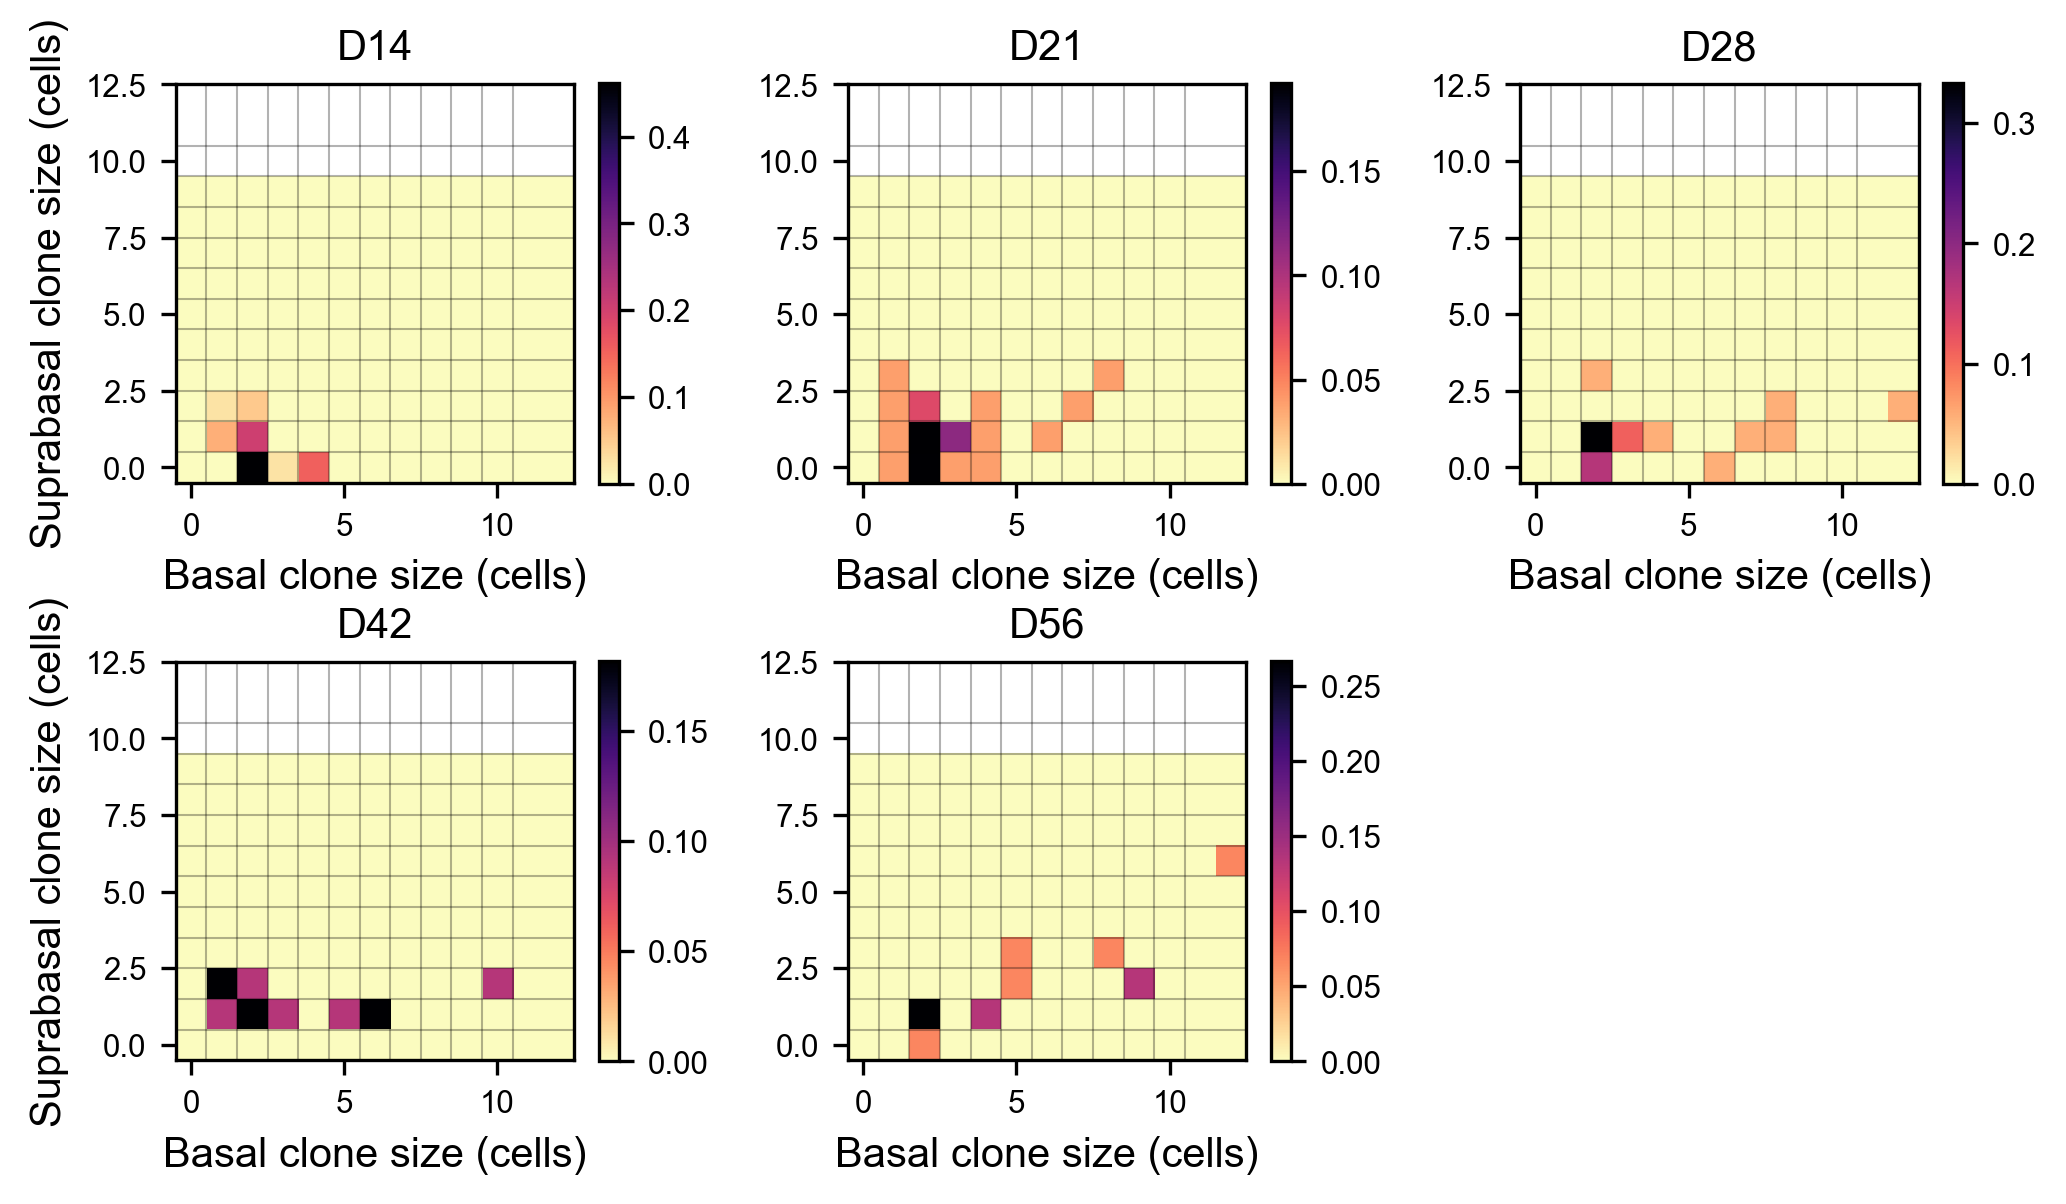

M1


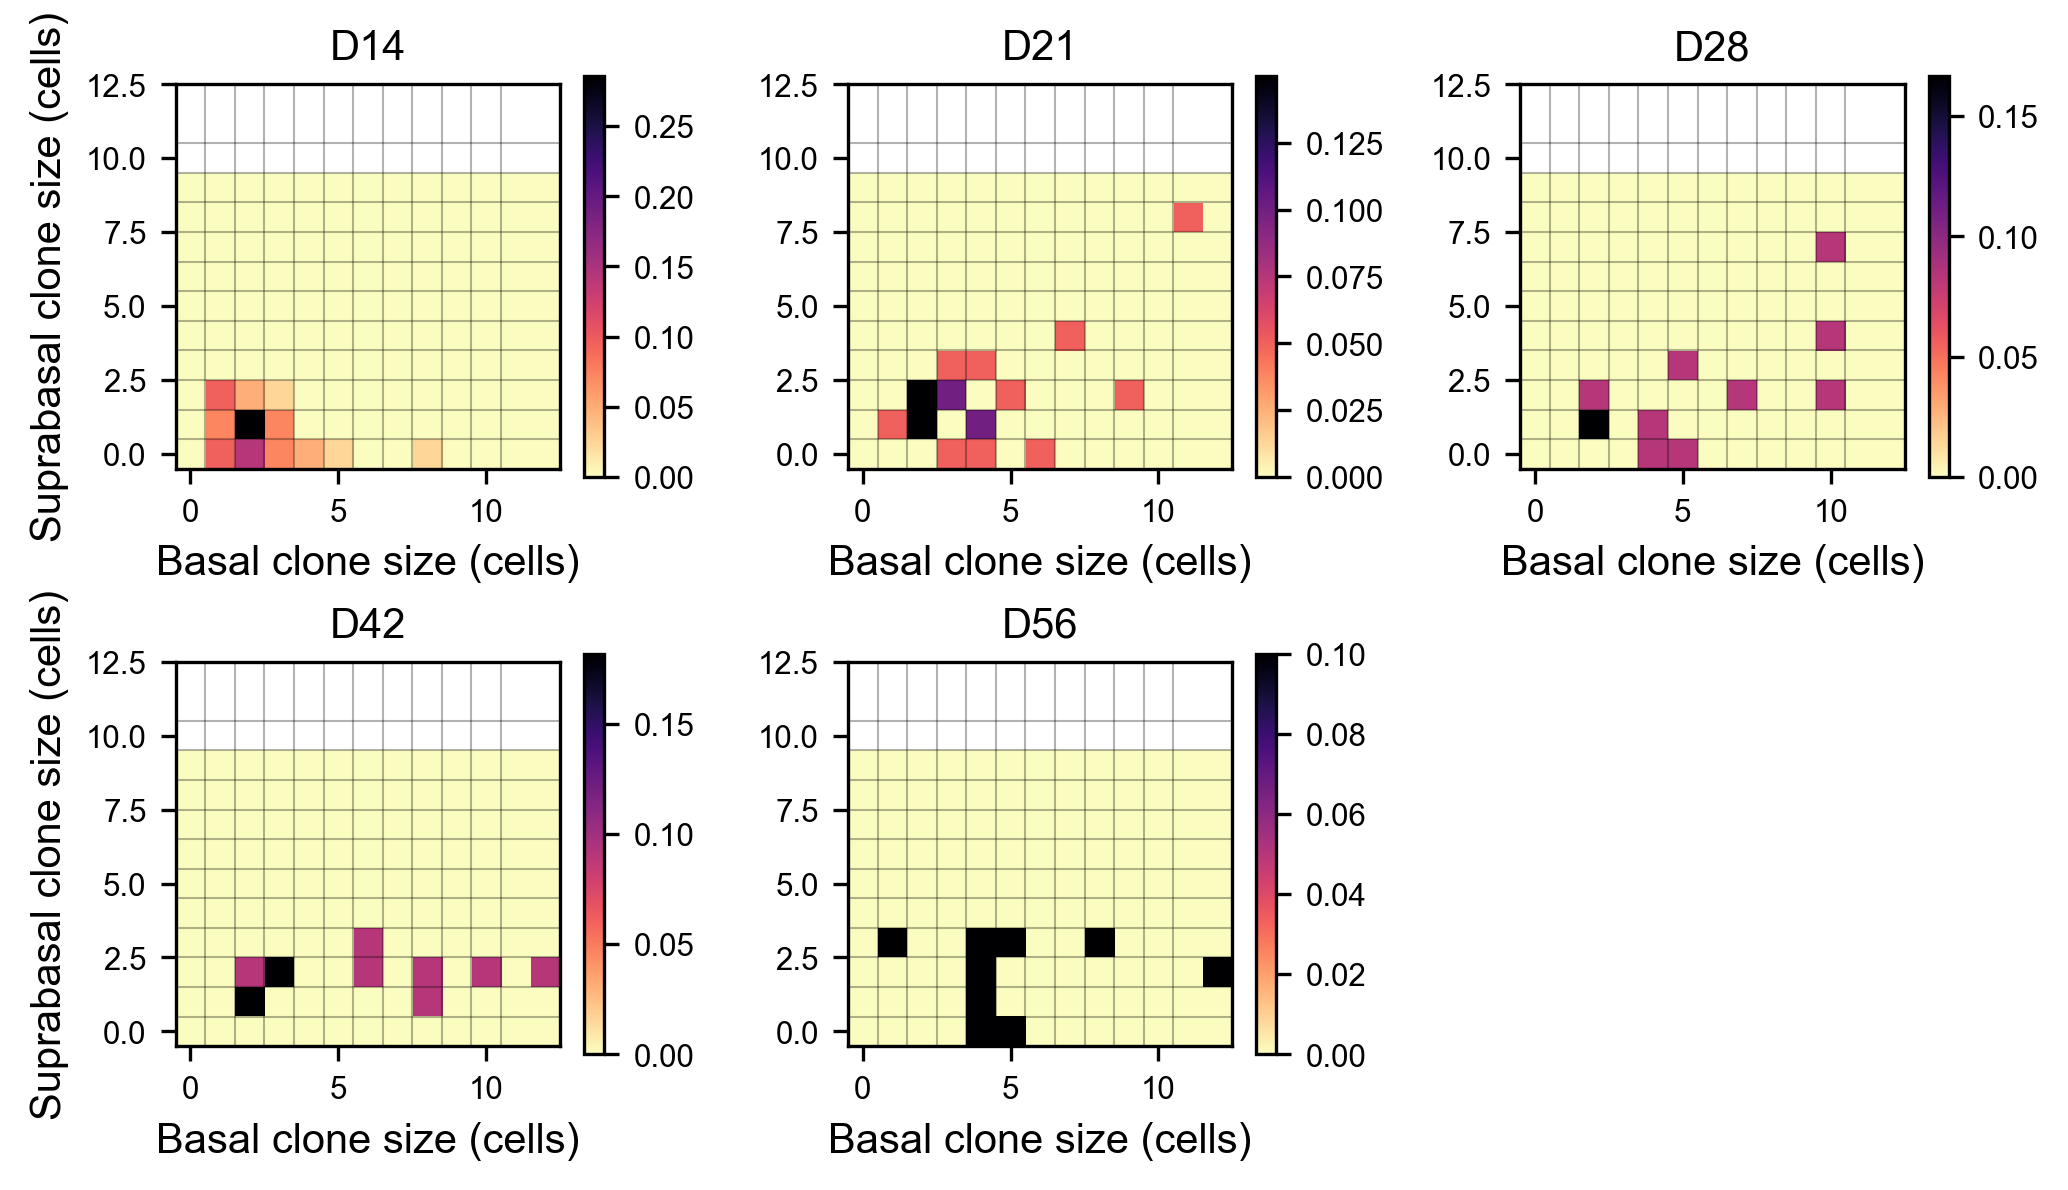

M14


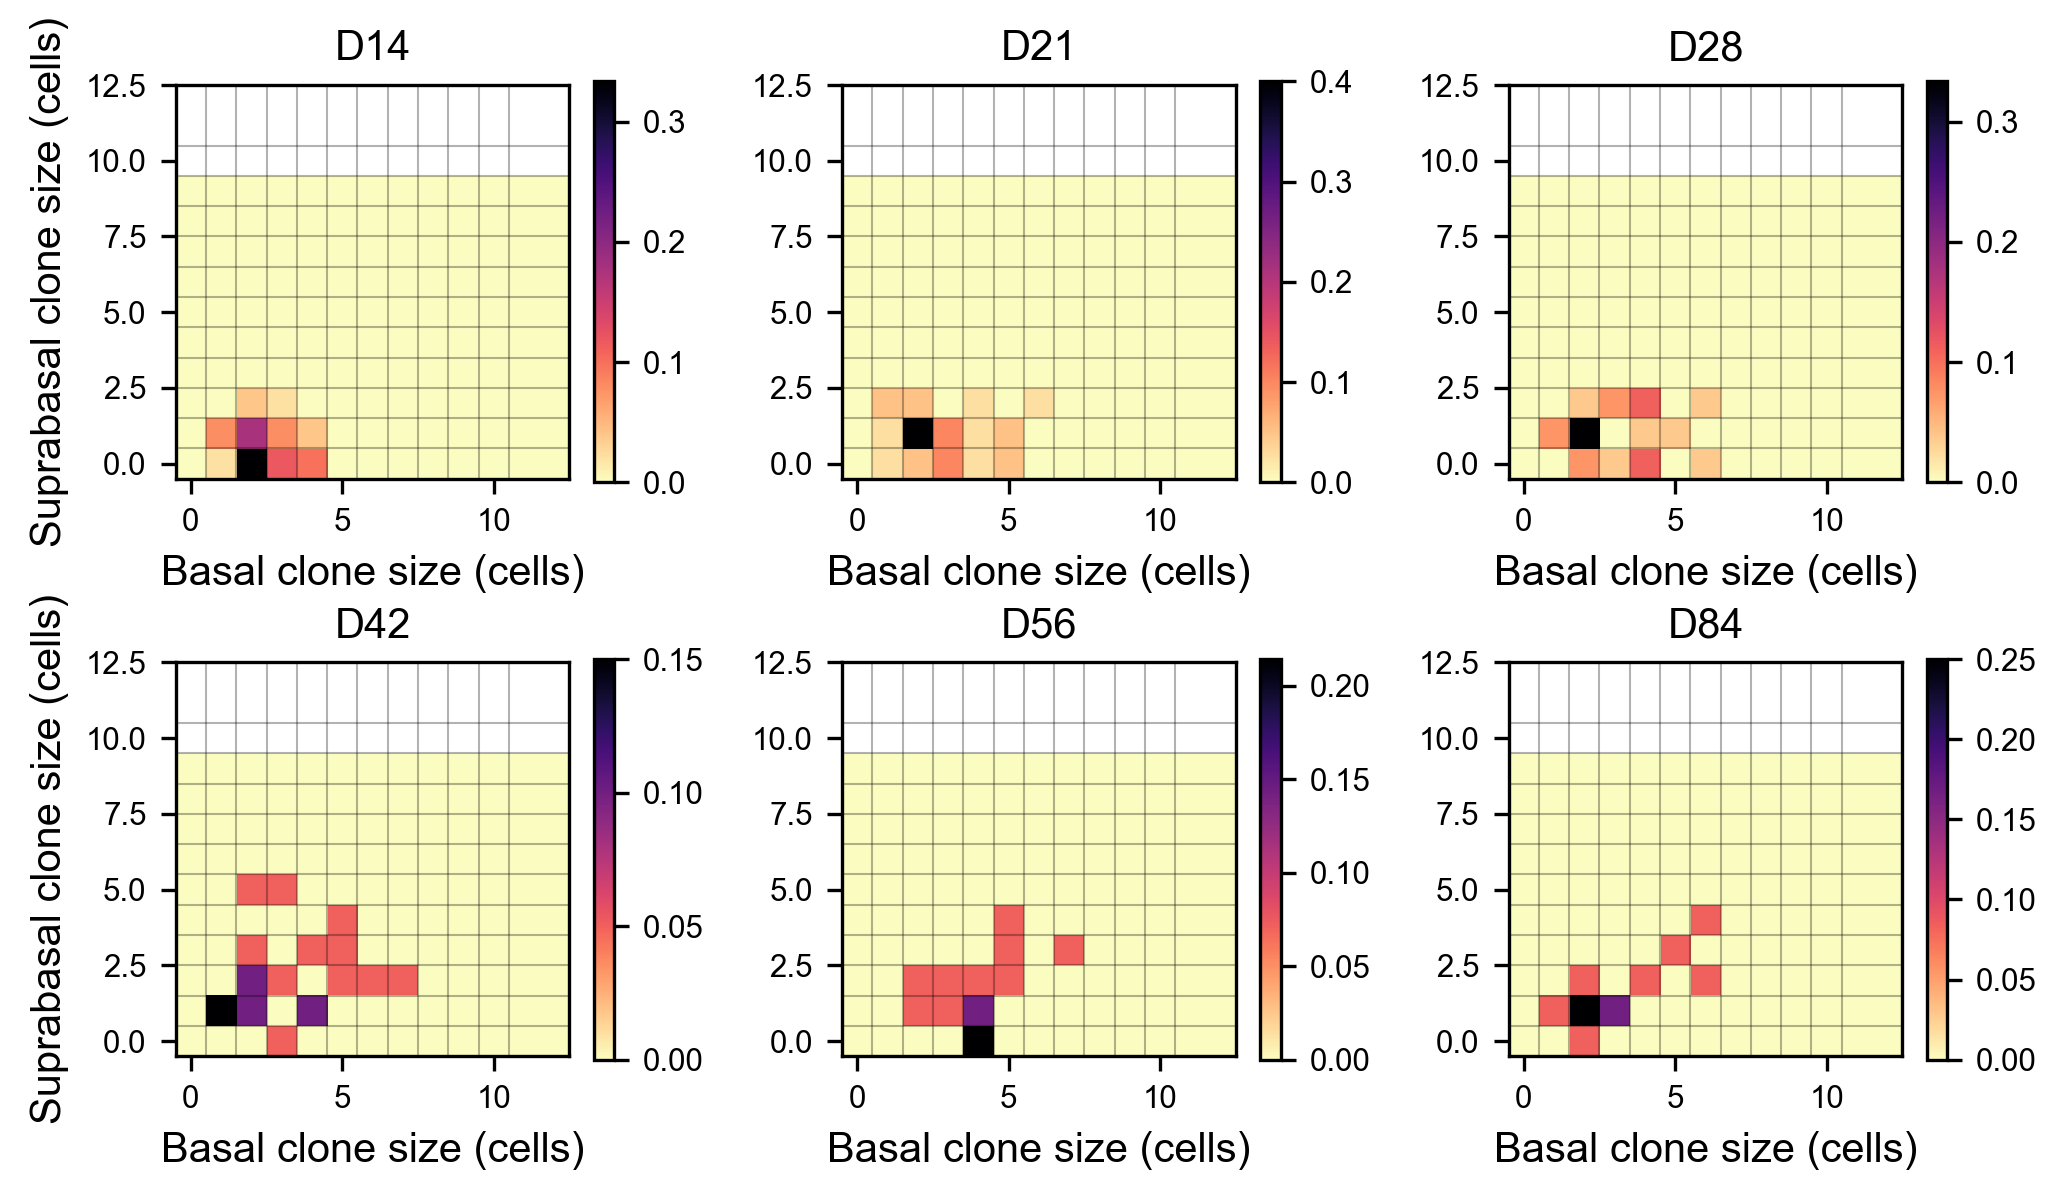

M3


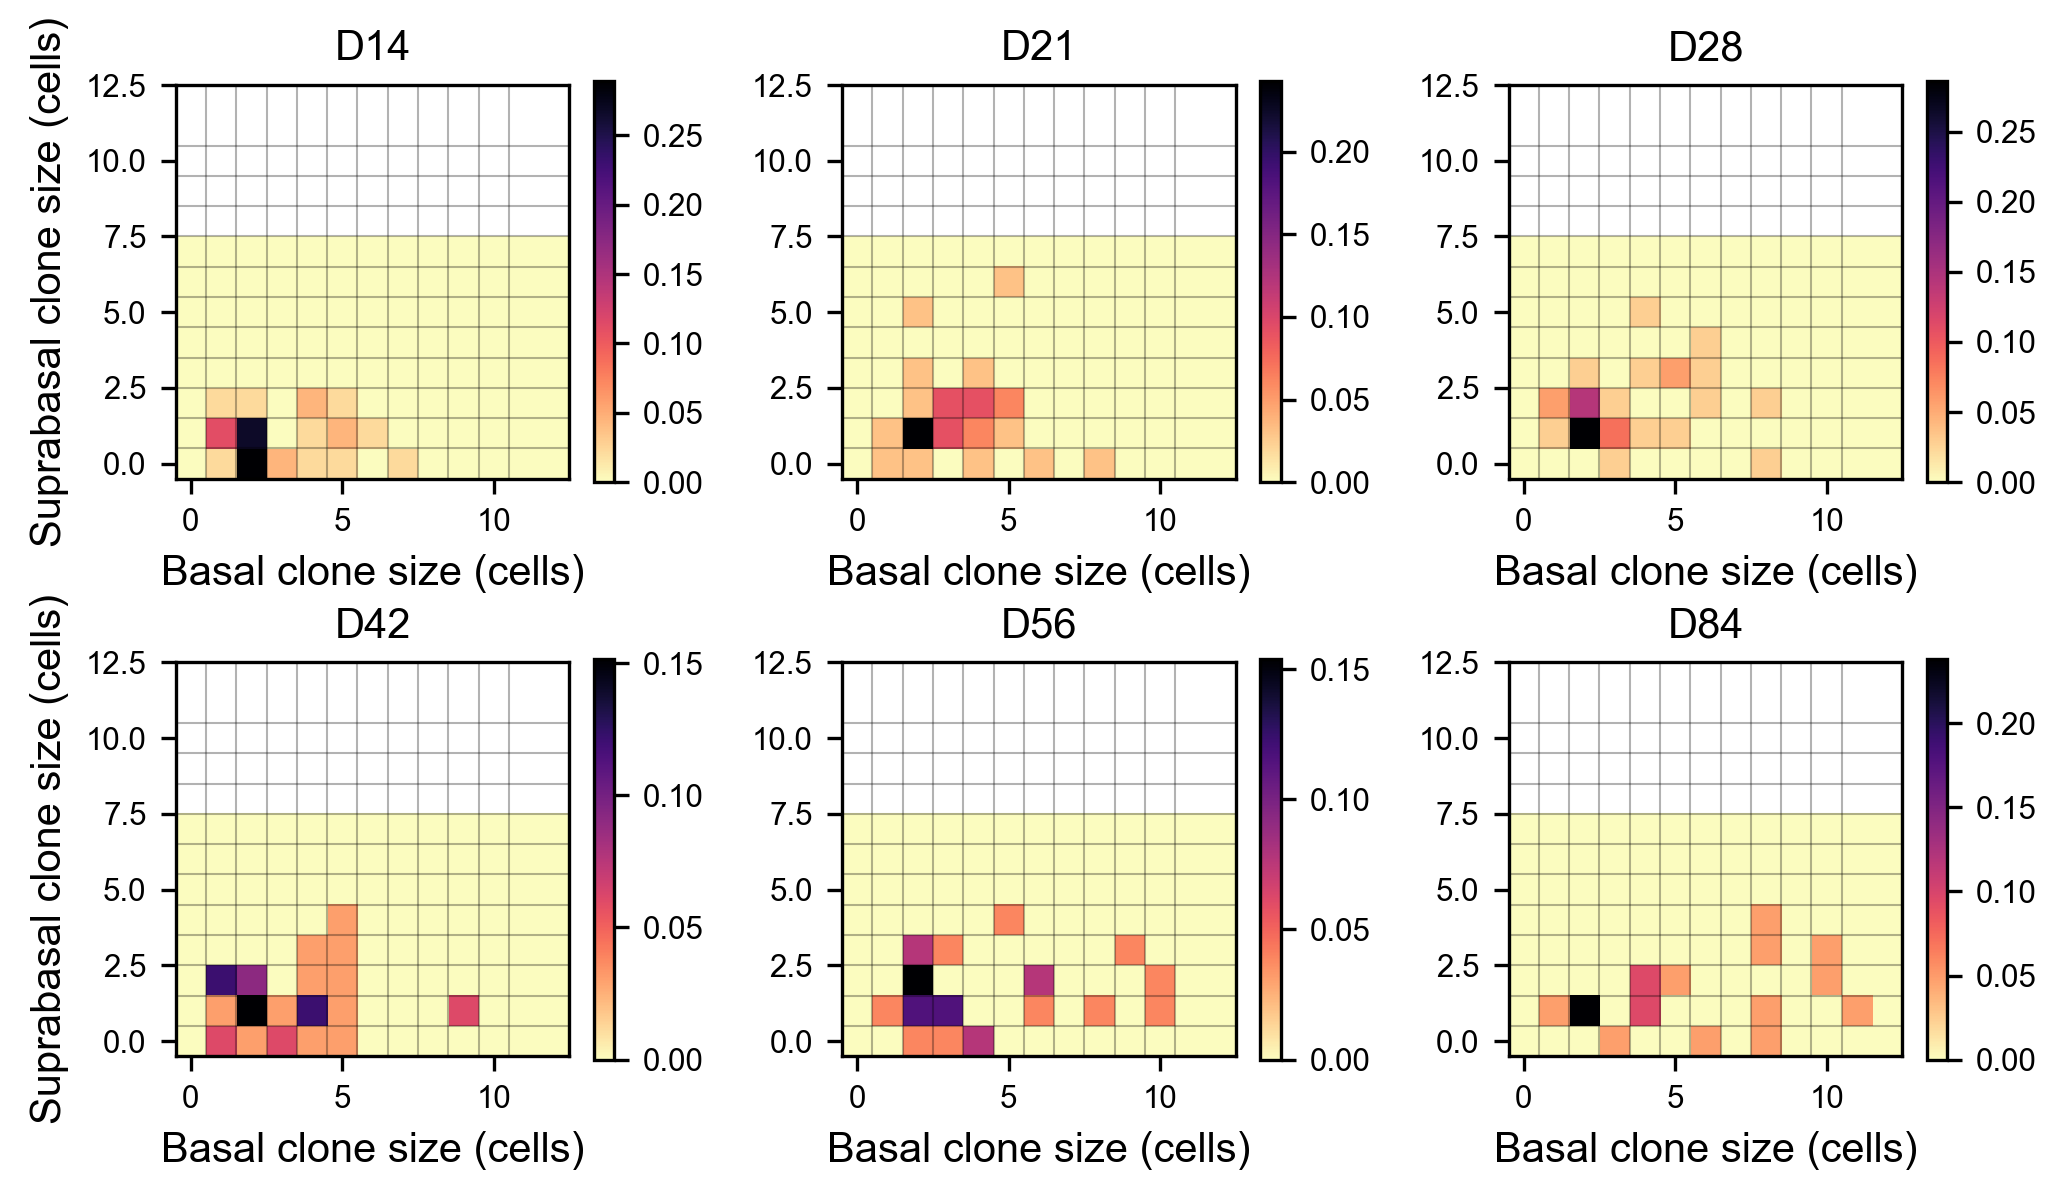

M1bis


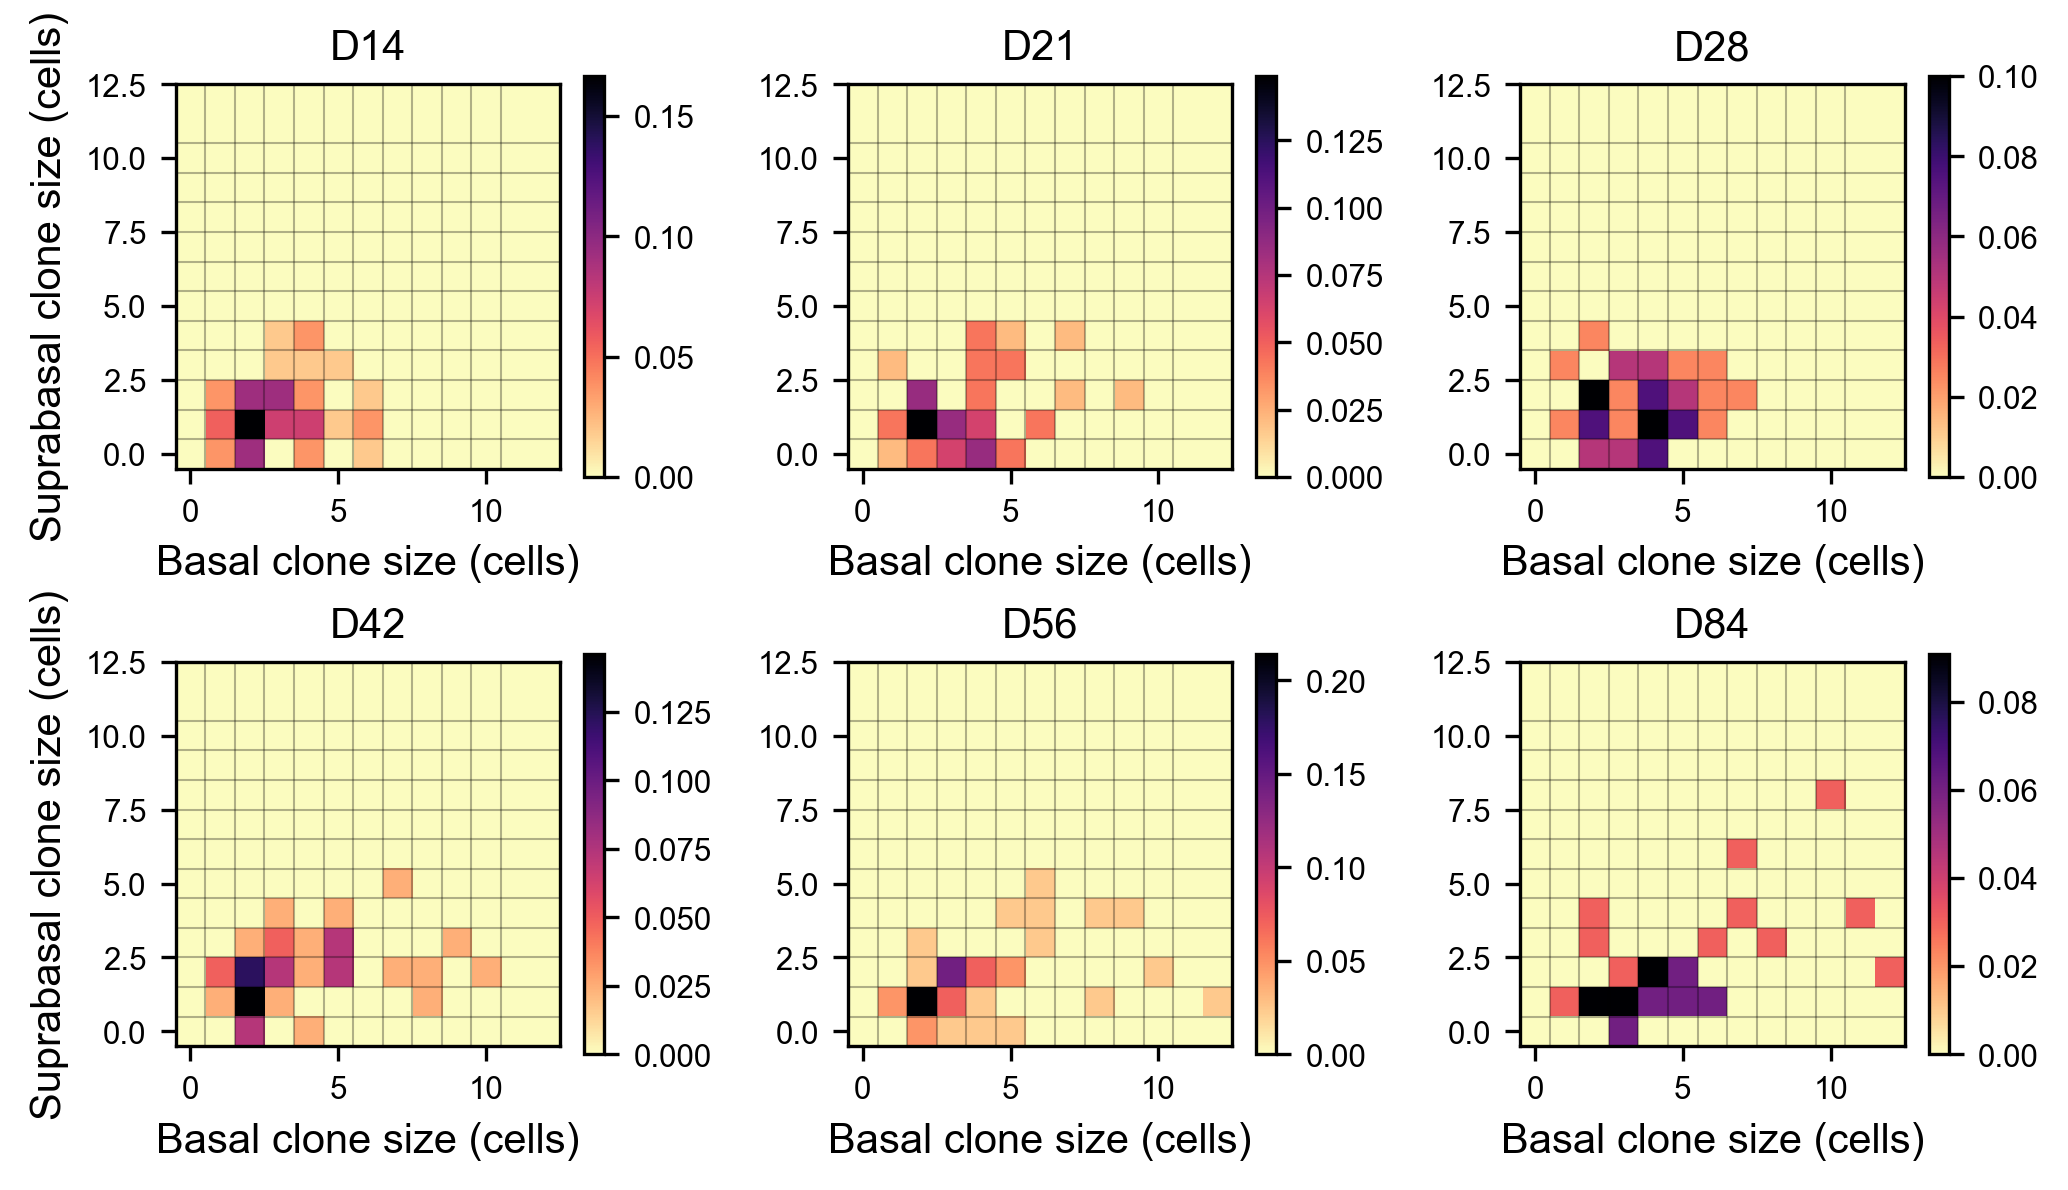

F3


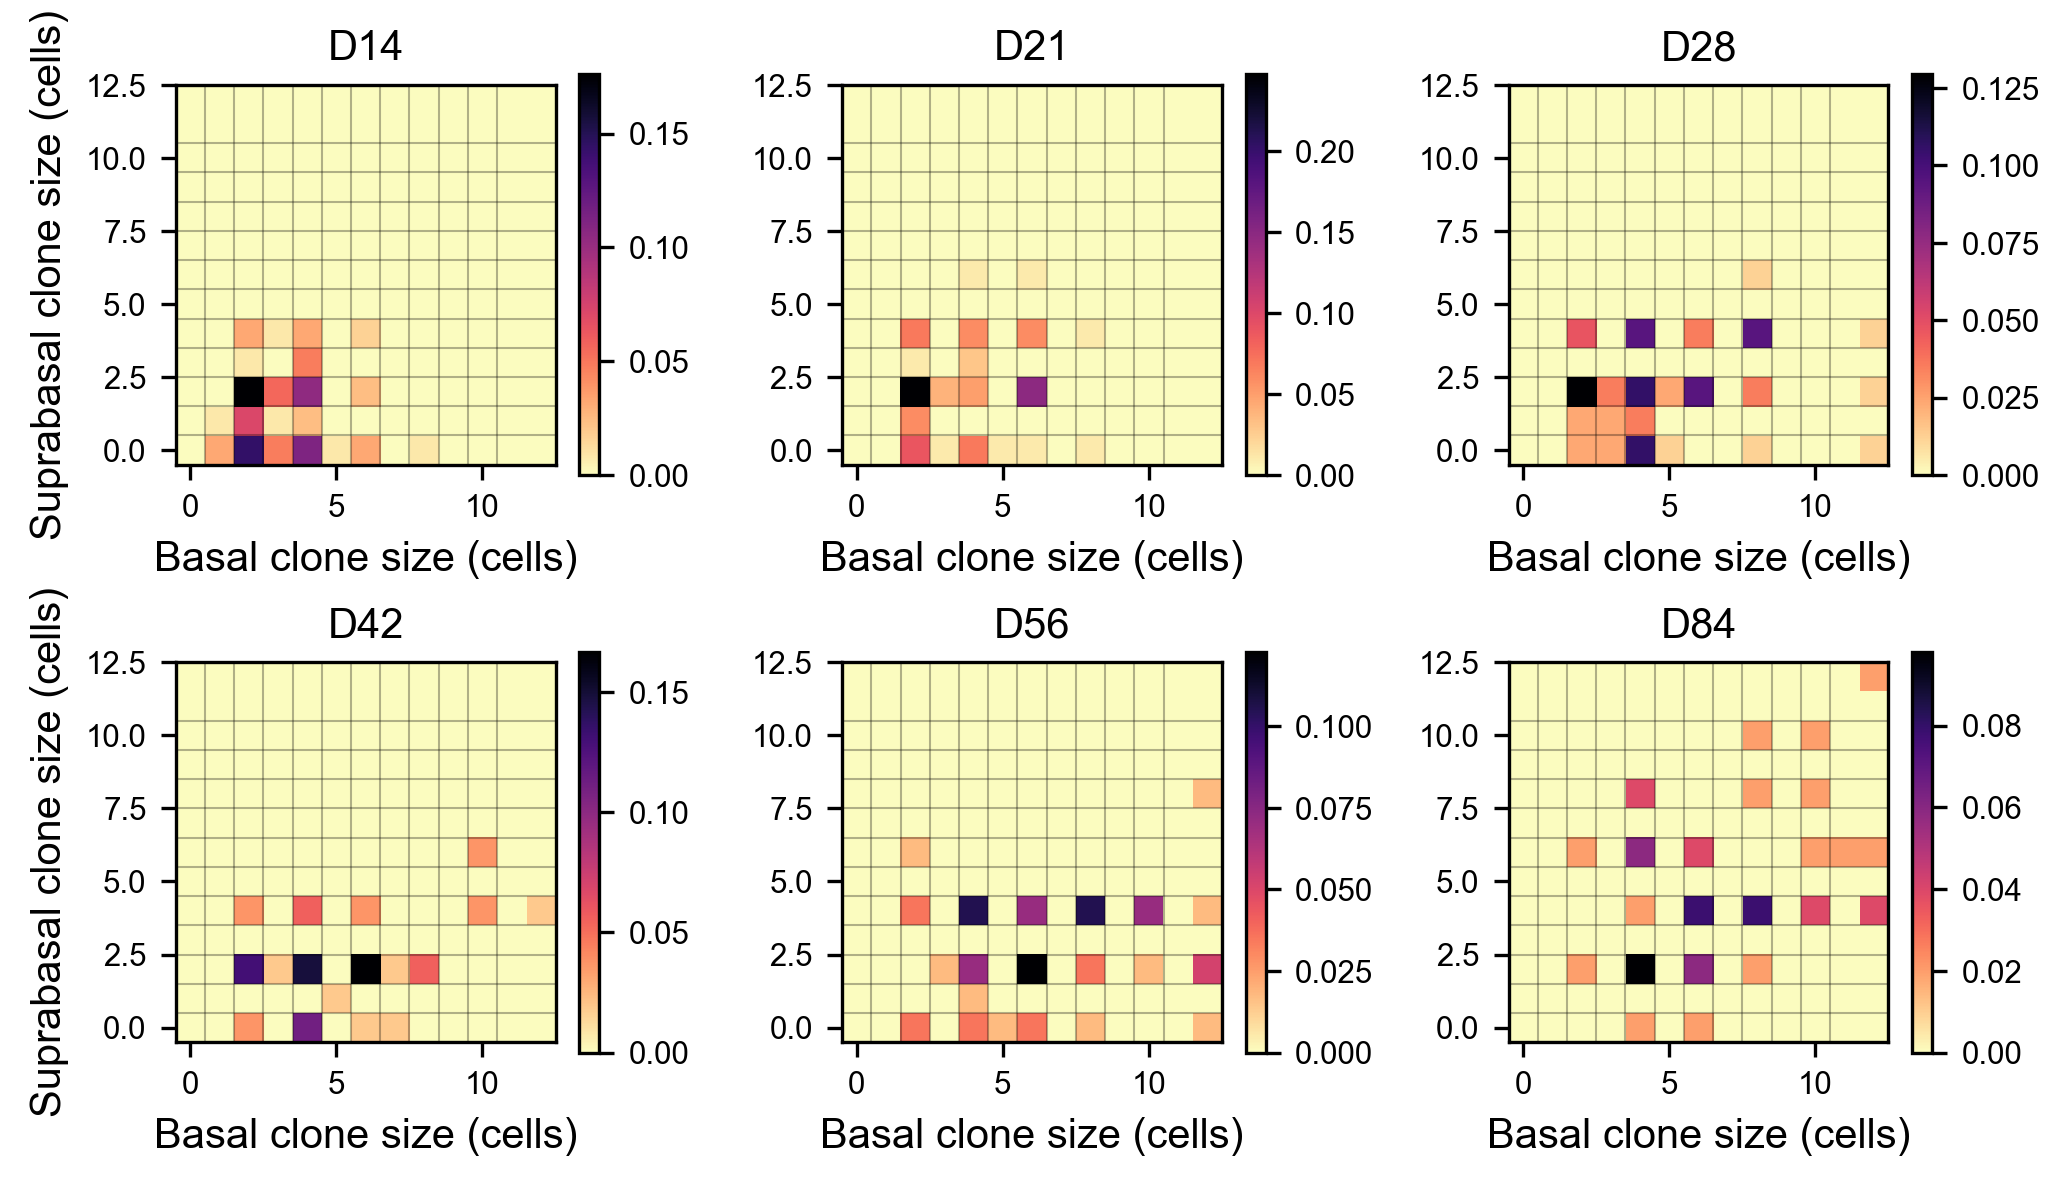

F4


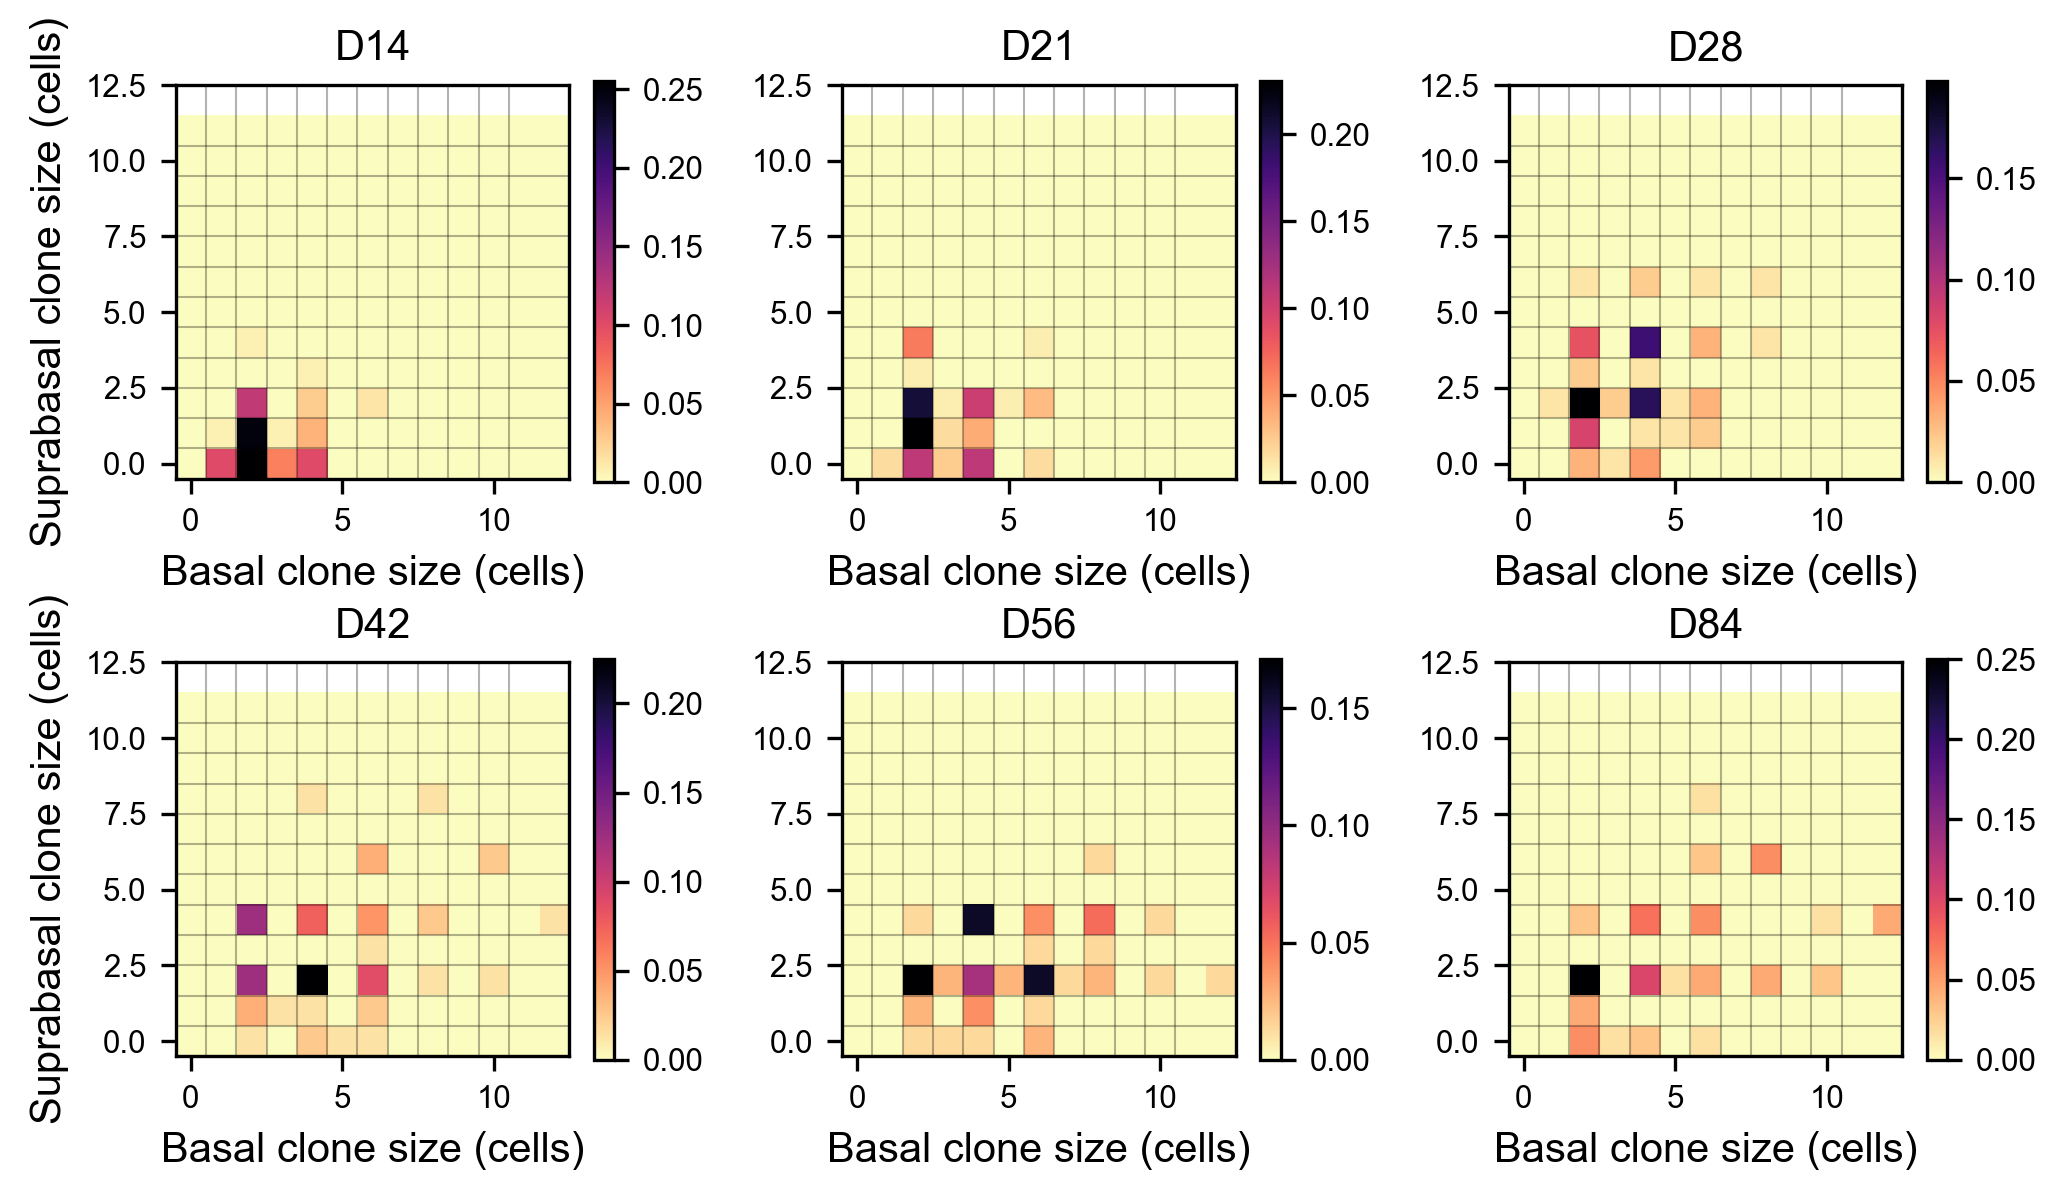

F11


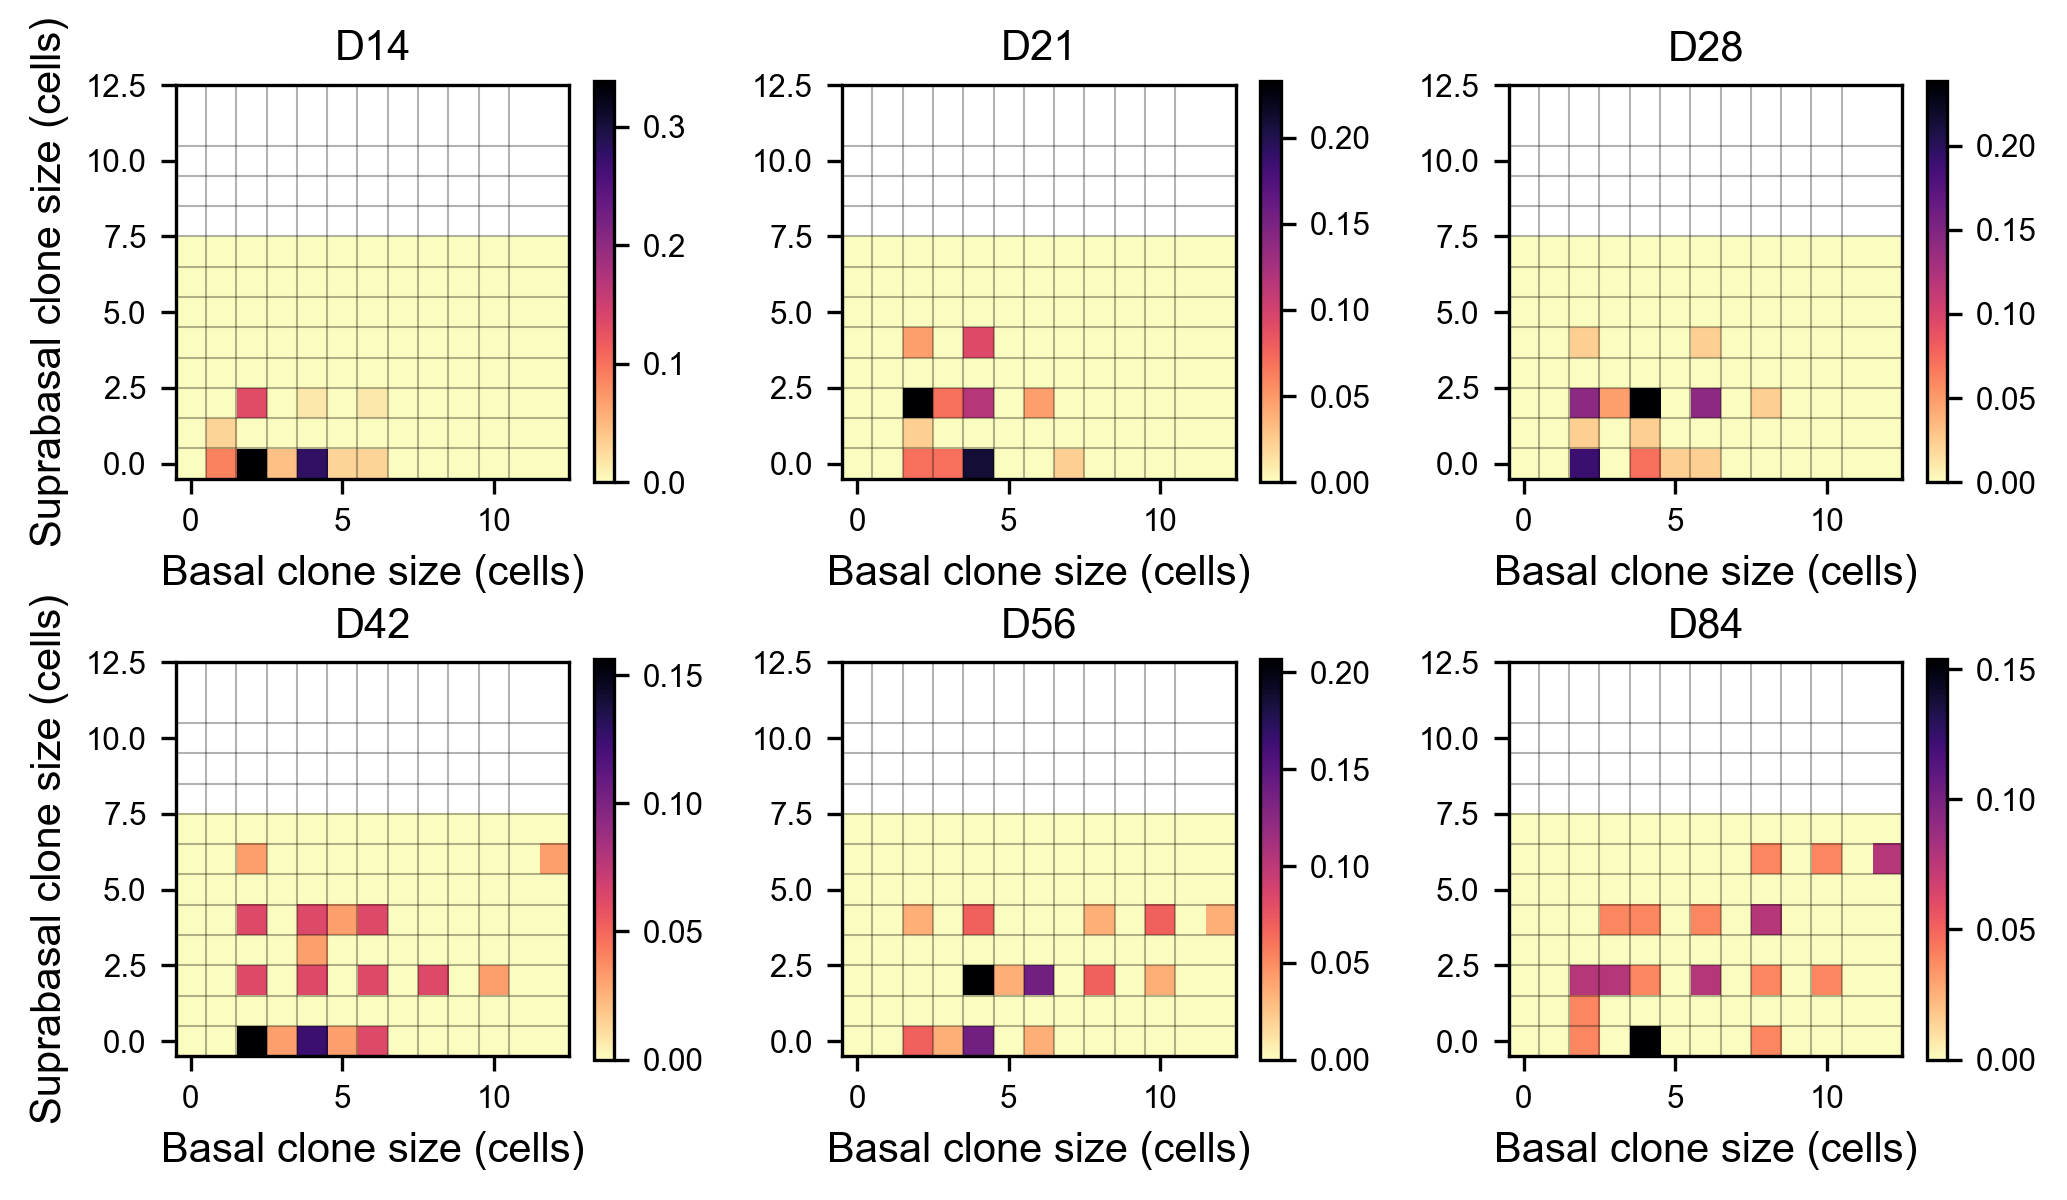

F9


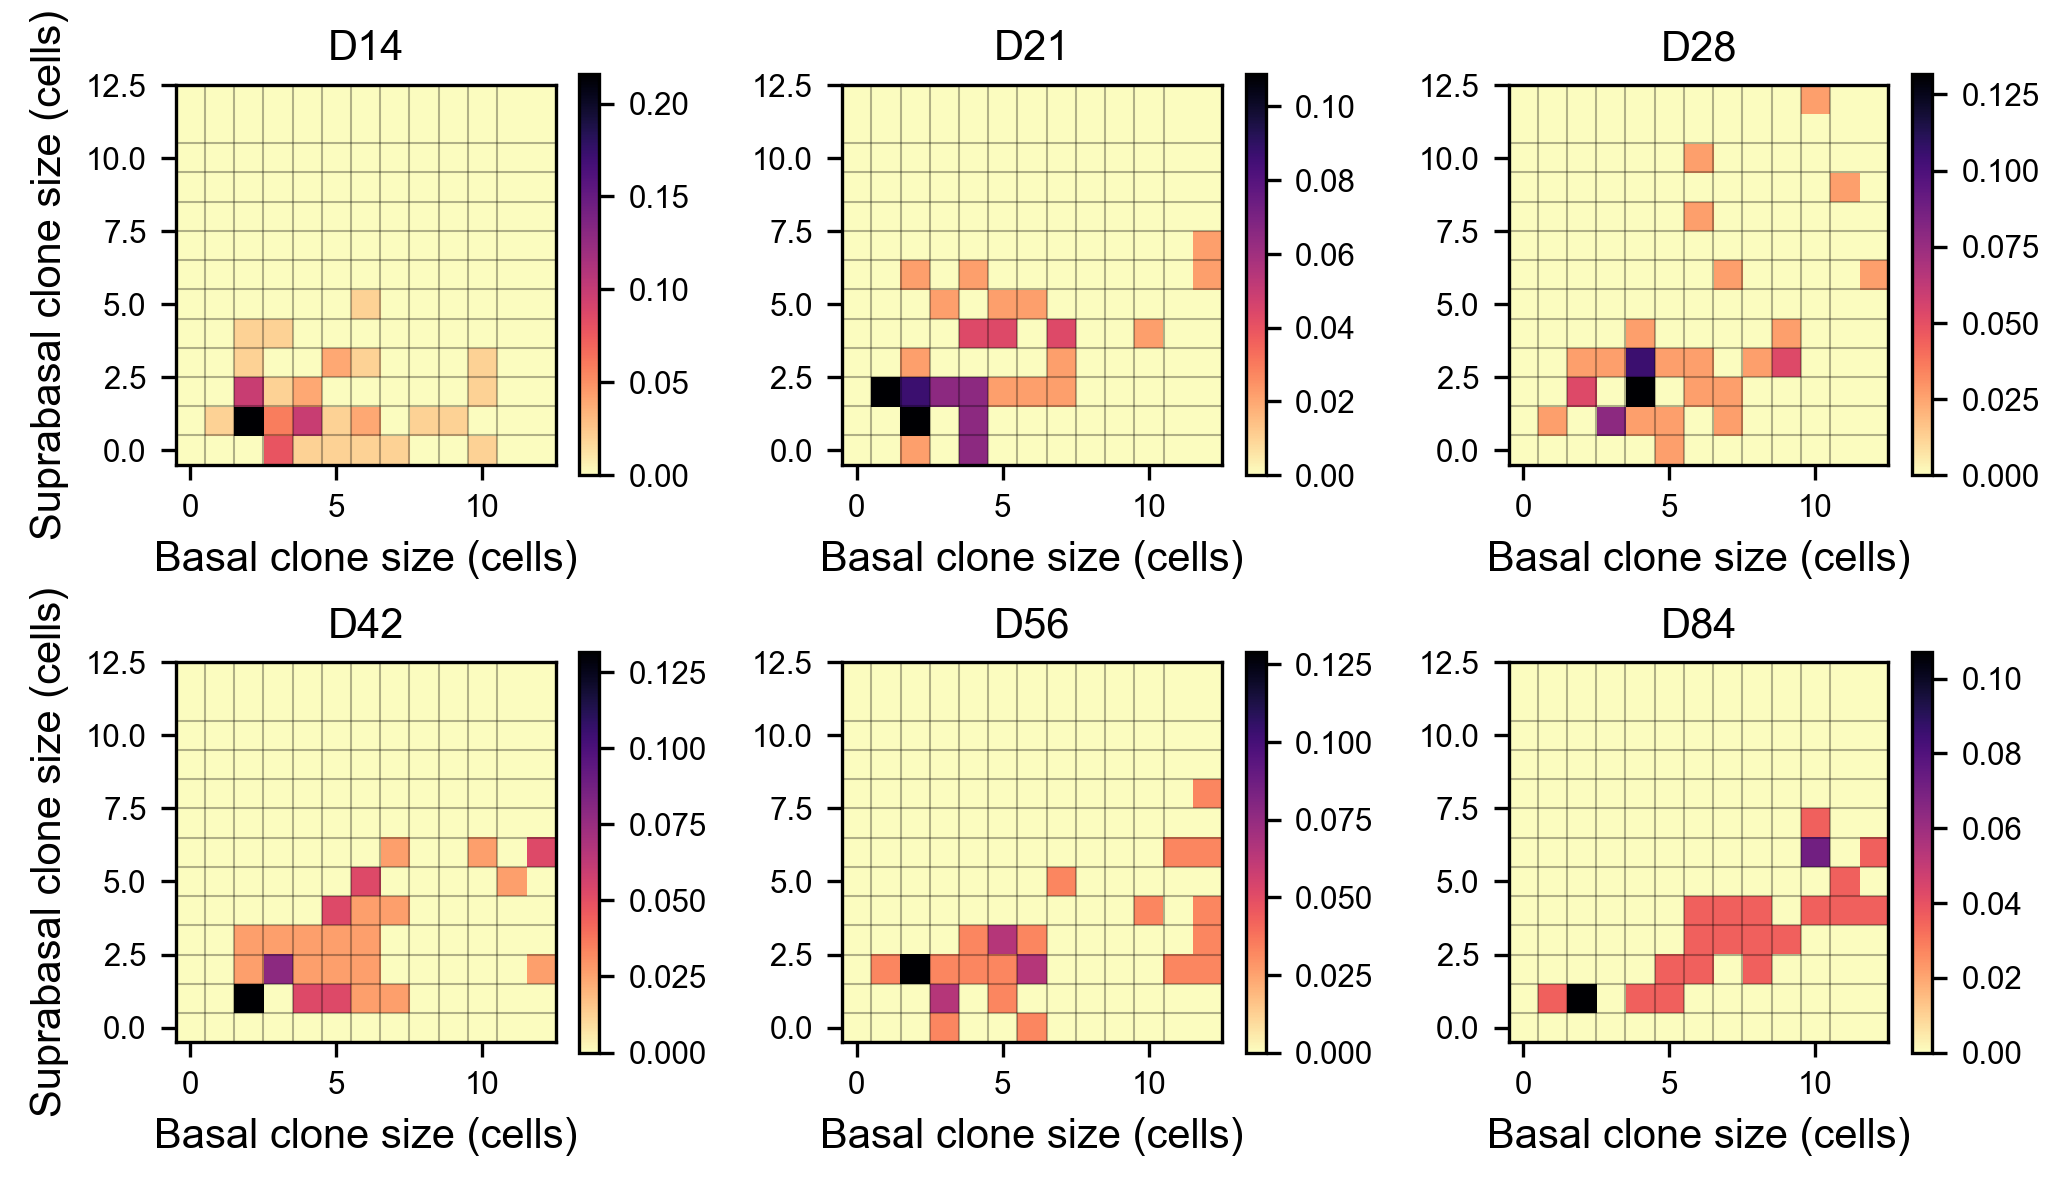

F10


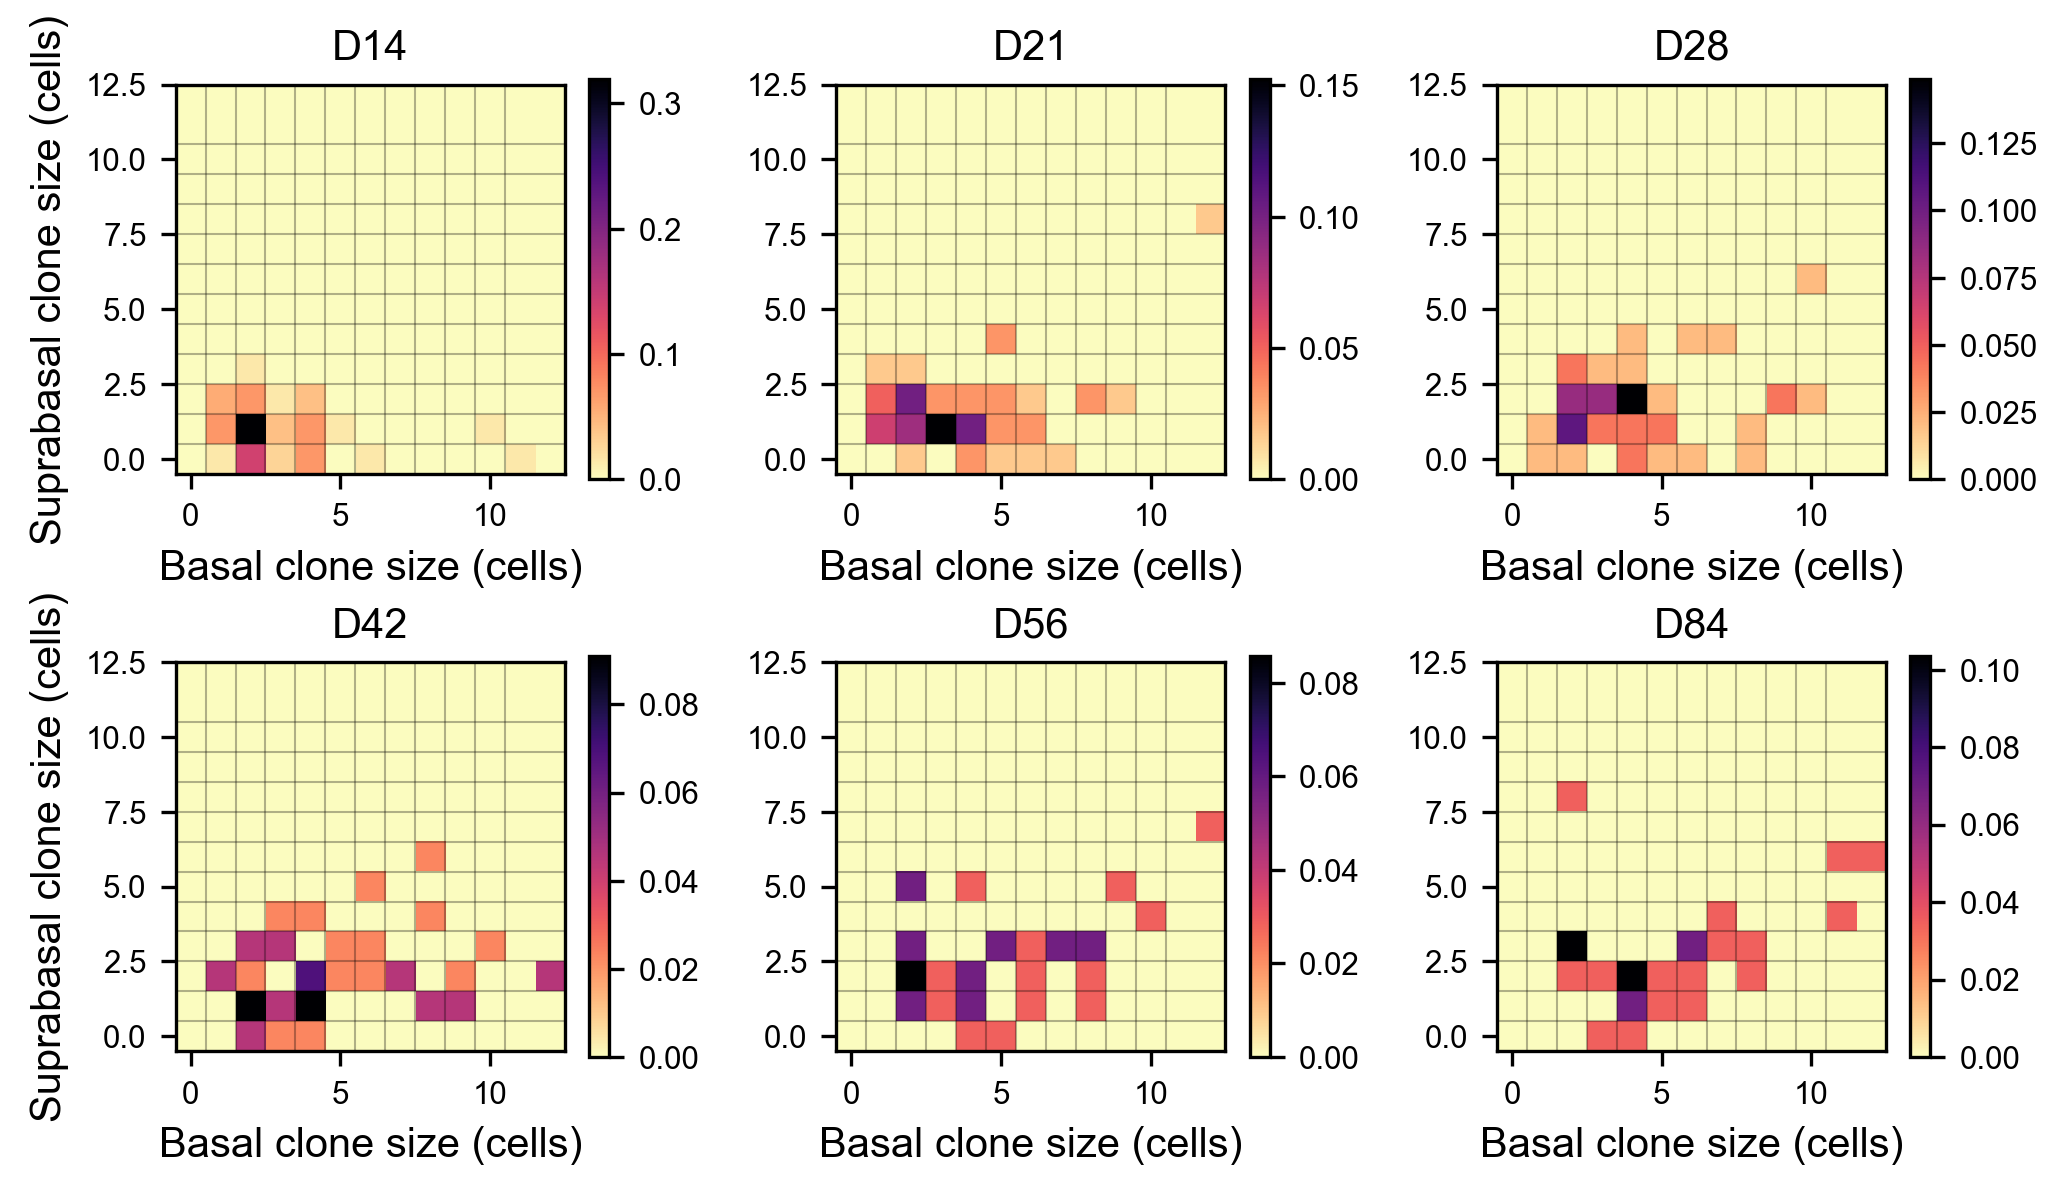

FileNotFoundError: [Errno 2] No such file or directory: '../../experiment/homeo/dan_2412_castre.pkl'

In [19]:
for sex in ['M', 'F']:
    print(sex)
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.figure(figsize=[7,4], dpi = 300)
    for t in range(1, len(clone_anal.tvals)-1):
        plt.subplot(2, 3, t)
        plt.imshow(clone_anal.joint_bas_sb[t,:,:].T, origin='lower', cmap = 'magma_r')
        plt.colorbar()
        plt.xlabel('Basal clone size (cells)')
        if (t-1) % 3 == 0:
            plt.ylabel('Suprabasal clone size (cells)')
        plt.vlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.xlim([-0.5, 12.5])
        plt.ylim([-0.5, 12.5])
        plt.title('Day ' + str(int(clone_anal.tvals[t])))
    plt.tight_layout()
    plt.show()

for sex in mmice + fmice:
    print(sex)
    exp_data = load_object(exp_folder + 'data_' + ct + '_' + sex + '.pkl')
    cpdf = exp_data['ctrpdf']
    livesize = exp_data['livesize']
    clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
    plt.figure(figsize=[7,4], dpi = 300)
    for t in range(1, len(clone_anal.tvals)-1):
        plt.subplot(2, 3, t)
        plt.imshow(clone_anal.joint_bas_sb[t,:,:].T, origin='lower', cmap = 'magma_r')
        plt.colorbar()
        plt.xlabel('Basal clone size (cells)')
        if (t-1) % 3 == 0:
            plt.ylabel('Suprabasal clone size (cells)')
        plt.vlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.hlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
        plt.xlim([-0.5, 12.5])
        plt.ylim([-0.5, 12.5])
        plt.title('D' + str(int(clone_anal.tvals[t])))
    plt.tight_layout()
    plt.show()



exp_data = load_object(exp_folder + 'dan_2412_castre.pkl')
cpdf = exp_data['ctrpdf']
livesize = exp_data['livesize']
clone_anal = clones.xanalysis(livesize, verbose = False, tvals = exp_data['ctrTimeClonesize'])
plt.figure(figsize=[7,4], dpi = 300)
for t in range(1, len(clone_anal.tvals)-1):
    plt.subplot(2, 3, t)
    plt.imshow(clone_anal.joint_bas_sb[t,:,:].T, origin='lower', cmap = 'magma_r')
    plt.colorbar()
    plt.xlabel('Basal clone size (cells)')
    if (t-1) % 3 == 0:
        plt.ylabel('Suprabasal clone size (cells)')
    plt.vlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
    plt.hlines(np.arange(0,12) - 0.5, -0.5, 12.5, color = 'k', linestyles='-', alpha = 0.3, linewidth = 0.5)
    plt.xlim([-0.5, 12.5])
    plt.ylim([-0.5, 12.5])
    plt.title('Day ' + str(int(clone_anal.tvals[t])))
plt.tight_layout()
plt.show()